# Brújula Soporte IT · Análisis exploratorio del SLA

**Fase 4 del proyecto: análisis de los factores que influyen en el cumplimiento del SLA.**

Brújula Soporte IT es una empresa **ficticia**. Los datos de tickets, clientes y agentes se han generado de forma sintética y reproducible. En cambio, los datos meteorológicos (Open-Meteo) y el calendario de festivos de Madrid (Nager.Date y BOCM) proceden de fuentes reales.

El conjunto de datos incorpora seis relaciones definidas previamente (Ficha §2.3). El objetivo de este análisis es comprobar si las técnicas aplicadas permiten identificarlas, cuantificar su importancia y reconocer los resultados que no ofrecen evidencia suficiente.

| Bloque | Contenido | Pregunta de la Ficha |
|---|---|---|
| 0 · Preparación | Conexión a PostgreSQL y carga de las vistas | — |
| 0.1 · Calidad de datos | Nulos, duplicados, rangos imposibles, cuadres | — |
| 1 · Descriptivo | Tiempos de resolución y valores atípicos | P1 |
| 2 · Estacionalidad | Mes, día de la semana, post-festivo | P3 |
| 3 · Pareto ABC | Concentración de la penalización | P2 |
| 4 · Contexto externo | Calor frente a vacaciones | P3 |
| 5 · Perfiles de cliente | K-Means | P6 |
| 6 · Previsión | Prophet: volumen y agentes en agosto | P4 |
| 7 · Riesgo de incumplir | Regresión logística | P5 |
| 8 · Hallazgos | Conclusiones y propuestas de mejora | — |

> **Nota sobre los importes:** se aplican los límites contractuales de penalización (−3,5 %) y bonificación (+3 %) por cliente y sprint (Ficha §0.3). Por este motivo, los importes difieren de los presentados en la fase 2, donde no se aplicaban estos límites.

## 0 · Preparación

Los datos se obtienen de las **vistas** del esquema `servicedesk`, las mismas que utiliza Power BI. De esta forma, ambos análisis parten de criterios de cálculo comunes.

La conexión reutiliza `01_etl/comun.py` y obtiene las credenciales del archivo `.env`, sin incluir contraseñas en el notebook.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

RAIZ = Path.cwd().parent if Path.cwd().name == "04_analysis" else Path.cwd()
sys.path.insert(0, str(RAIZ / "01_etl"))
from comun import config  # noqa: E402  (lee el .env de la raíz)

OUT = RAIZ / "04_analysis" / "outputs"
OUT.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings("ignore", category=FutureWarning)

motor = create_engine(URL.create(
    "postgresql+psycopg2", username=config("DB_USER"), password=config("DB_PASSWORD"),
    host=config("DB_HOST"), port=int(config("DB_PORT")), database=config("DB_NAME")))
ESQUEMA = config("DB_SCHEMA")

def leer(vista: str) -> pd.DataFrame:
    return pd.read_sql(f"SELECT * FROM {ESQUEMA}.{vista}", motor)

tickets      = leer("v_ticket_enriquecido")   # 1 fila por ticket
dias         = leer("v_kpis_diarios")         # 1 fila por día del calendario
cli_sprint   = leer("v_cumplimiento_sprint")  # cliente × sprint, con tramo y € (con tope)
perfil       = leer("v_perfil_cliente")       # 1 fila por cliente
pareto_dep   = leer("v_pareto_penalizacion")  # departamento × tipo

for nombre, df in [("tickets", tickets), ("dias", dias), ("cli_sprint", cli_sprint),
                   ("perfil", perfil), ("pareto_dep", pareto_dep)]:
    print(f"{nombre:<11} {df.shape[0]:>6} filas × {df.shape[1]:>2} columnas")

tickets      25300 filas × 50 columnas
dias           733 filas × 24 columnas
cli_sprint    1235 filas × 20 columnas
perfil          40 filas × 20 columnas
pareto_dep      10 filas ×  8 columnas


Se utiliza la misma **paleta de colores** que en Power BI para mantener la coherencia visual entre los entregables. Los gráficos se exportan en formato PNG a 150 ppp.

In [2]:
AZUL, AZUL_MEDIO, NARANJA = "#1F3A5F", "#2E6DB4", "#F28C4A"
VERDE, ROJO, GRIS, GRIS_CLARO = "#1E7B5C", "#C0392B", "#605E5C", "#D5DAE1"

sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": GRIS_CLARO, "grid.color": "#ECEFF3", "axes.titleweight": "bold",
    "axes.titlesize": 13, "axes.titlecolor": AZUL, "axes.labelcolor": GRIS,
    "xtick.color": GRIS, "ytick.color": GRIS, "font.family": "Segoe UI"})

def guardar(fig, nombre: str):
    fig.savefig(OUT / nombre, dpi=150, bbox_inches="tight", facecolor="white")
    print(f"Guardado: 04_analysis/outputs/{nombre}")

def pct(x, dec=1):
    return f"{x:.{dec}f} %".replace(".", ",")

def eur(x):
    return f"{x:,.0f} €".replace(",", ".")

## 0.1 · Calidad de datos

Antes de comenzar, revisamos la calidad de los datos mediante cuatro comprobaciones:

1. **Duplicados:** cada registro debe tener una clave única.
2. **Valores nulos:** comprobamos si corresponden a situaciones válidas, como tickets abiertos que todavía no tienen fecha de resolución.
3. **Coherencia de valores:** buscamos duraciones negativas, fechas inconsistentes y porcentajes fuera de rango.
4. **Conciliación entre vistas:** verificamos que las penalizaciones atribuidas a los tickets coincidan con las de facturación.

In [3]:
# 1. Duplicados por clave
claves = {"tickets": (tickets, ["ticket_id"]), "dias": (dias, ["fecha"]),
          "cli_sprint": (cli_sprint, ["cliente_id", "sprint_id"]), "perfil": (perfil, ["cliente_id"])}
for nombre, (df, clave) in claves.items():
    print(f"{nombre:<11} duplicados por {'+'.join(clave):<22} {df.duplicated(subset=clave).sum()}")

tickets     duplicados por ticket_id              0
dias        duplicados por fecha                  0
cli_sprint  duplicados por cliente_id+sprint_id   0
perfil      duplicados por cliente_id             0


In [4]:
# 2. Nulos en tickets: ¿en qué columnas y en qué estado del ticket?
nulos = tickets.isna().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
print("Columnas con nulos en tickets (de", len(tickets), "filas):")
print(nulos.to_string())

print("\nNulos por estado del ticket (filas = estado, columnas = campo vacío):")
cols_nulas = nulos.index.tolist()
tabla_nulos = tickets[cols_nulas].isna().groupby(tickets["estado_actual"]).sum()
tabla_nulos.insert(0, "tickets", tickets["estado_actual"].value_counts())
tabla_nulos

Columnas con nulos en tickets (de 25300 filas):
fecha_cancelacion          24588
fecha_incumplimiento       23388
fecha_cierre                1002
fecha_resolucion             855
fecha_medicion               836
sprint_medicion              836
cumple_resolucion            836
min_resolucion_sla           712
pct_sla_consumido            712
horas_sla_resolucion         712
agente_id                    240
agente                       240
seniority                    240
fecha_primera_respuesta       12
min_respuesta_sla             12
cumple_respuesta              12

Nulos por estado del ticket (filas = estado, columnas = campo vacío):


,tickets,fecha_cancelacion,fecha_incumplimiento,fecha_cierre,fecha_resolucion,fecha_medicion,sprint_medicion,cumple_resolucion,min_resolucion_sla,pct_sla_consumido,horas_sla_resolucion,agente_id,agente,seniority,fecha_primera_respuesta,min_respuesta_sla,cumple_respuesta
estado_actual,,,,,,,,,,,,,,,,,
Abierto,23,23,23,23,23,23,23,23,0,0,0,12,12,12,12,12,12
Cancelado,712,0,712,712,712,712,712,712,712,712,712,228,228,228,0,0,0
Cerrado,24298,24298,22430,0,0,0,0,0,0,0,0,0,0,0,0,0,0
En curso,110,110,91,110,110,91,91,91,0,0,0,0,0,0,0,0,0
Esperando al cliente,10,10,10,10,10,10,10,10,0,0,0,0,0,0,0,0,0
Resuelto,147,147,122,147,0,0,0,0,0,0,0,0,0,0,0,0,0


Guardado: 04_analysis/outputs/00_calidad_datos.png


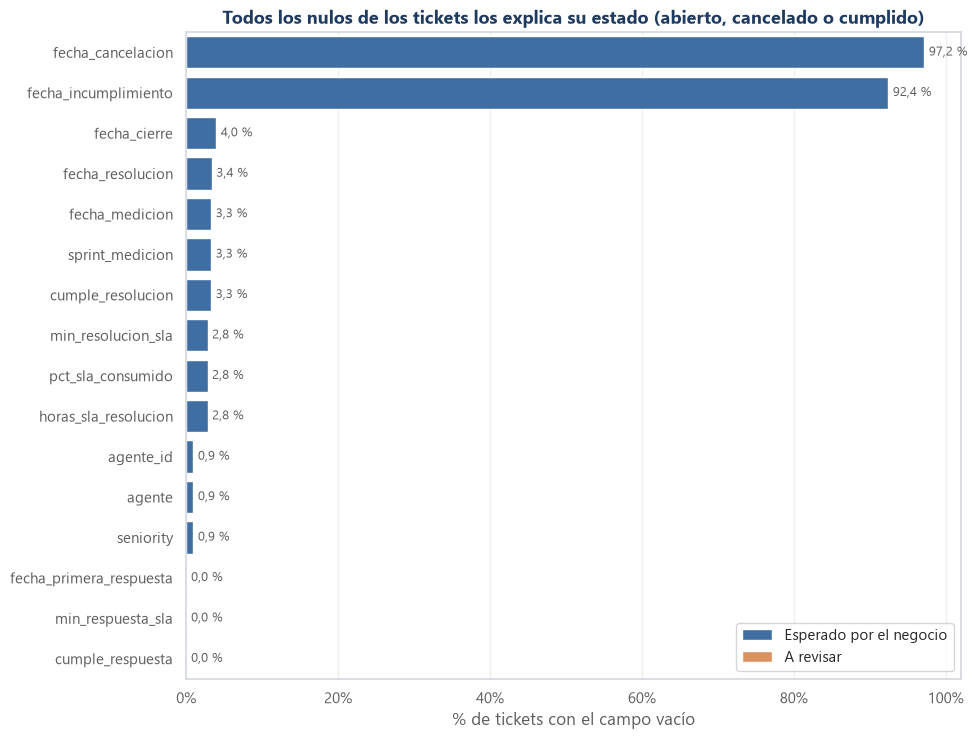

In [5]:
# Gráfico: % de nulos por columna, distinguiendo los que explica el estado del ticket
estados_abiertos = ["Abierto", "En curso", "Esperando al cliente"]
esperado = {
    "fecha_cancelacion":       "solo existe si se cancela",
    "fecha_incumplimiento":    "solo existe si incumple",
    "fecha_cierre":            "abiertos, resueltos aún sin cerrar y cancelados",
    "fecha_resolucion":        "abiertos y cancelados",
    "cumple_resolucion":       "abiertos y cancelados (no se mide)",
    "fecha_primera_respuesta": "cancelados antes de responder / abiertos",
    "cumple_respuesta":        "cancelados antes de responder / abiertos",
    "fecha_medicion":          "abiertos en plazo y cancelados (aún no se miden)",
    "sprint_medicion":         "abiertos en plazo y cancelados (aún no se miden)",
    "min_resolucion_sla":      "cancelados (el reloj se descarta)",
    "pct_sla_consumido":       "cancelados (el reloj se descarta)",
    "horas_sla_resolucion":    "cancelados (el reloj se descarta)",
    "agente_id":               "cancelados antes de asignar y abiertos sin asignar",
    "agente":                  "cancelados antes de asignar y abiertos sin asignar",
    "seniority":               "cancelados antes de asignar y abiertos sin asignar",
}
datos = (nulos / len(tickets) * 100).rename("pct").reset_index().rename(columns={"index": "columna"})
datos["tipo"] = np.where(datos["columna"].isin(esperado), "Esperado por el negocio", "A revisar")

fig, ax = plt.subplots(figsize=(10, 0.45 * len(datos) + 1.2))
sns.barplot(data=datos, y="columna", x="pct", hue="tipo", dodge=False, ax=ax,
            palette={"Esperado por el negocio": AZUL_MEDIO, "A revisar": NARANJA})
for i, r in datos.iterrows():
    ax.text(r.pct + 0.6, i, pct(r.pct), va="center", fontsize=9, color=GRIS)
ax.set(xlabel="% de tickets con el campo vacío", ylabel="",
       title="Todos los nulos de los tickets los explica su estado (abierto, cancelado o cumplido)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend(title="", loc="lower right")
guardar(fig, "00_calidad_datos.png")
plt.show()

In [6]:
# 3. Valores imposibles: cada regla debe dar 0 filas
t = tickets
reglas = {
    "minutos de SLA negativos":                   (t[["min_respuesta_sla", "min_resolucion_sla", "min_pausa"]] < 0).any(axis=1),
    "1ª respuesta antes de la creación":          t.fecha_primera_respuesta < t.fecha_creacion,
    "resolución antes de la creación":            t.fecha_resolucion < t.fecha_creacion,
    "cierre antes de la resolución":              t.fecha_cierre < t.fecha_resolucion,
    "P1 en algo que no es incidencia":            (t.prioridad == "P1") & (t.tipo != "Incidencia"),
    "penalización atribuida negativa":            t.penalizacion_atribuida_eur < 0,
    "% de SLA consumido negativo":                t.pct_sla_consumido < 0,
    "cumple pero superó el objetivo de minutos":  (t.cumple_resolucion == True) & (t.min_resolucion_sla > t.objetivo_resolucion_min),
    "día: temperatura fuera de −15…48 °C":        ~dias.temp_max.between(-15, 48),
    "día: % de ausentes fuera de 0–100":          ~dias.pct_agentes_ausentes.between(0, 100),
    "cliente × sprint: % cumplimiento fuera 0–100": ~cli_sprint.pct_cumplimiento.between(0, 100),
    "cliente × sprint: ajuste fuera del tope":    ~cli_sprint.pct_ajuste.between(-3.5, 3.0),
}
resultado = pd.Series({k: int(v.sum()) for k, v in reglas.items()}, name="filas que la incumplen")
resultado.to_frame()

,filas que la incumplen
minutos de SLA negativos,0
1ª respuesta antes de la creación,0
resolución antes de la creación,0
cierre antes de la resolución,0
P1 en algo que no es incidencia,0
penalización atribuida negativa,0
% de SLA consumido negativo,0
cumple pero superó el objetivo de minutos,0
día: temperatura fuera de −15…48 °C,0
día: % de ausentes fuera de 0–100,0


In [7]:
# 4. Cuadres entre vistas
pen_tickets  = tickets.penalizacion_atribuida_eur.sum()
pen_factura  = -cli_sprint.loc[cli_sprint.ajuste_eur < 0, "ajuste_eur"].sum()
pen_perfil   = perfil.penalizacion_eur.abs().sum()   # en esta vista va con signo negativo
pen_pareto   = pareto_dep.penalizacion_eur.sum()
print(f"Penalización repartida en tickets ...... {eur(pen_tickets):>12}")
print(f"Penalización en cliente × sprint ....... {eur(pen_factura):>12}")
print(f"Penalización en el perfil de cliente ... {eur(pen_perfil):>12}")
print(f"Penalización en el Pareto ............... {eur(pen_pareto):>12}")

balance = cli_sprint.groupby("anio_sprint").ajuste_eur.sum().round(0)
print("\nBalance neto (bonus − penalización) por año, con tope:")
print(balance.map(eur).to_string())

sin_agente = tickets[tickets.agente_id.isna()]
print(f"\nTickets sin agente asignado: {len(sin_agente)} →",
      sin_agente.estado_actual.value_counts().to_dict())

Penalización repartida en tickets ......    142.513 €
Penalización en cliente × sprint .......    142.513 €
Penalización en el perfil de cliente ...    142.513 €
Penalización en el Pareto ...............    142.513 €

Balance neto (bonus − penalización) por año, con tope:
anio_sprint
2024    -31.743 €
2025    -36.322 €

Tickets sin agente asignado: 240 → {'Cancelado': 228, 'Abierto': 12}


### Resultados y conclusiones del bloque 0.1

- **Sin duplicados** en ninguna clave (ticket, día, cliente × sprint, cliente).
- **Los valores nulos detectados responden a reglas de negocio**, por lo que no se consideran errores.
  `fecha_incumplimiento` está vacía en el 92,4 % porque esos tickets **cumplieron**; se comprobó en las
  dos direcciones: los 1.912 incumplidos tienen fecha y ningún cumplido la tiene. Los 240 tickets sin
  agente son 228 cancelados antes de asignarse y 12 abiertos en cola. Estos campos deben mantenerse vacíos cuando no corresponde informar un valor; completarlos artificialmente alteraría el análisis.
- **No se detectan valores inconsistentes** en las 12 reglas (minutos negativos, fechas al revés, P1 fuera de
  incidencias, ajustes fuera del tope…).
- **Las vistas cuadran**: 142.513 € de penalización en las cuatro; balance −31.743 € (2024) y
  −36.322 € (2025), las mismas cifras que el informe de Power BI.

**Conclusión:** las comprobaciones realizadas permiten continuar con el análisis sin aplicar transformaciones adicionales de limpieza.


## 1 · Descriptivo

**Objetivo del análisis (pregunta 1):** ¿qué % de tickets cumple el SLA por tipo, prioridad y nivel de contrato,
y qué clientes caen por debajo de su objetivo o quedan a menos de 1 punto del tramo deficiente?

Para comparar tickets con objetivos muy distintos (un P1 tiene horas; un P4, días) usamos el
**% de SLA consumido**: minutos de reloj gastados ÷ minutos permitidos. El **100 % representa el límite establecido**: los valores inferiores indican que el plazo no se ha agotado, mientras que los superiores reflejan un exceso sobre el tiempo permitido. Así todas las prioridades se miden en la misma escala.

In [8]:
medidos = tickets[tickets.cumple_resolucion.notna()].copy()   # abiertos en plazo y cancelados no se miden
medidos["cumple"] = medidos.cumple_resolucion.astype(bool).astype(float)   # 1 = cumple (la columna llega como objeto por los nulos)
medidos["incumple"] = 1 - medidos.cumple

resumen = medidos.groupby("prioridad").agg(
    tickets=("ticket_id", "size"),
    mediana_pct_consumido=("pct_sla_consumido", "median"),
    p95_pct_consumido=("pct_sla_consumido", lambda s: s.quantile(0.95)),
    maximo_pct_consumido=("pct_sla_consumido", "max"),
    pct_incumple=("incumple", "mean"),
)
resumen["pct_incumple"] *= 100
resumen.round(1)

,tickets,mediana_pct_consumido,p95_pct_consumido,maximo_pct_consumido,pct_incumple
prioridad,,,,,
P1,393,39.6,109.8,181.7,6.9
P2,4040,42.0,111.5,570.1,7.2
P3,12780,43.6,115.3,407.5,8.1
P4,7251,43.8,114.8,676.4,7.8


**Valores atípicos (regla IQR):** un ticket es atípico si su % consumido supera
Q3 + 1,5 × (Q3 − Q1) de su prioridad. Estos casos se mantienen en el análisis para identificar los tickets con mayores desviaciones, especialmente relevantes por su posible impacto en las penalizaciones.

In [9]:
def atipicos(g):
    q1, q3 = g.pct_sla_consumido.quantile([0.25, 0.75])
    corte = q3 + 1.5 * (q3 - q1)
    at = g[g.pct_sla_consumido > corte]
    return pd.Series({"corte_iqr_pct": corte, "atipicos": len(at), "pct_de_la_prioridad": len(at) / len(g) * 100,
                      "pct_escalados_atipicos": at.es_escalado.astype(float).mean() * 100,
                      "pct_escalados_resto": g.drop(at.index).es_escalado.astype(float).mean() * 100})

tabla_atipicos = medidos.groupby("prioridad").apply(atipicos, include_groups=False).round(1)
tabla_atipicos

,corte_iqr_pct,atipicos,pct_de_la_prioridad,pct_escalados_atipicos,pct_escalados_resto
prioridad,,,,,
P1,104.5,24.0,6.1,45.8,35.2
P2,116.7,174.0,4.3,66.7,33.6
P3,118.3,583.0,4.6,65.9,33.2
P4,117.2,341.0,4.7,64.8,33.0


Guardado: 04_analysis/outputs/01_distribucion.png


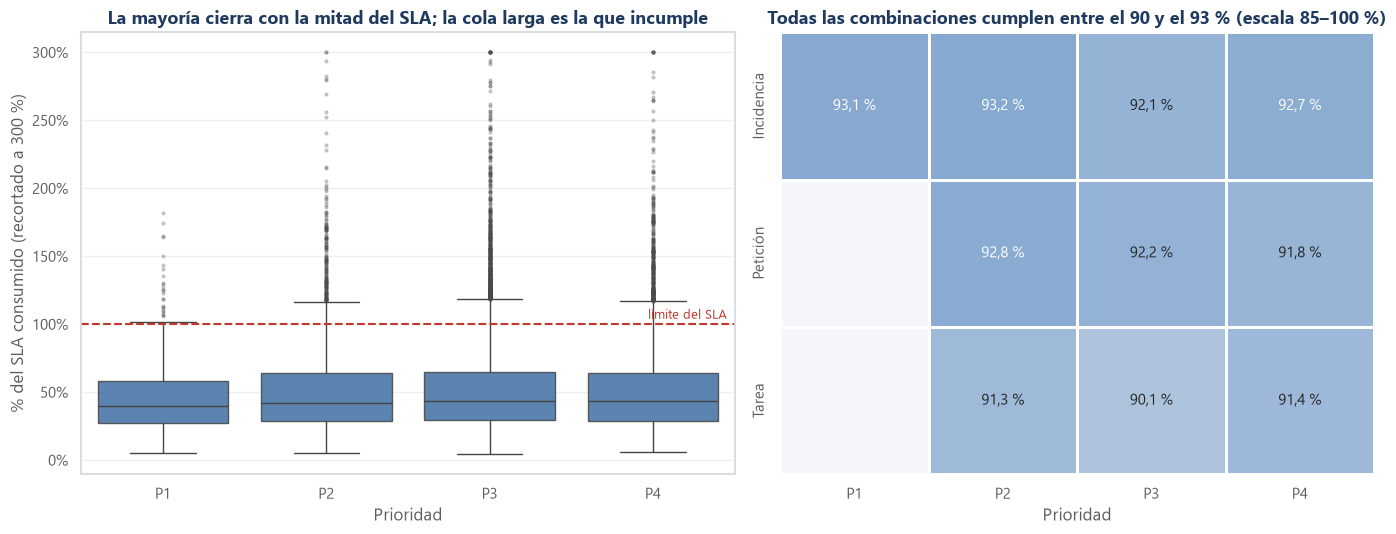

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})

# Izquierda: distribución del % de SLA consumido por prioridad (recortada a 300 % para que se lea)
ax = axes[0]
orden = ["P1", "P2", "P3", "P4"]
sns.boxplot(data=medidos, x="prioridad", y=medidos.pct_sla_consumido.clip(upper=300), order=orden,
            color=AZUL_MEDIO, fliersize=2, flierprops={"alpha": .25, "markerfacecolor": GRIS},
            boxprops={"alpha": .85}, ax=ax)
ax.axhline(100, color=ROJO, ls="--", lw=1.5)
ax.text(3.45, 104, "límite del SLA", color=ROJO, ha="right", fontsize=9)
ax.set(xlabel="Prioridad", ylabel="% del SLA consumido (recortado a 300 %)",
       title="La mayoría cierra con la mitad del SLA; la cola larga es la que incumple")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))

# Derecha: % de cumplimiento por tipo × prioridad
ax = axes[1]
mapa = (medidos.pivot_table(index="tipo", columns="prioridad", values="cumple", aggfunc="mean") * 100)
etiquetas = mapa.map(lambda v: "—" if pd.isna(v) else pct(v))   # P1 solo existe en incidencias
sns.heatmap(mapa, annot=etiquetas, fmt="", vmin=85, vmax=100, cmap=sns.light_palette(AZUL_MEDIO, as_cmap=True),
            cbar=False, linewidths=2, linecolor="white", ax=ax, annot_kws={"fontsize": 11})
ax.grid(False)
ax.set_facecolor("#F4F6F9")
ax.set(xlabel="Prioridad", ylabel="",
       title="Todas las combinaciones cumplen entre el 90 y el 93 % (escala 85–100 %)")
plt.tight_layout()
guardar(fig, "01_distribucion.png")
plt.show()

### Cumplimiento por nivel de contrato y clientes en riesgo

Cada nivel tiene su **objetivo contractual** (Gold 95 %, Silver 90 %, Bronze 85 %). Miramos tres cosas:
cumplimiento por tipo × prioridad × nivel, clientes que no alcanzan el objetivo anual y sprints situados a menos de un punto porcentual del tramo de penalización.

In [11]:
OBJETIVO = {"Gold": 95, "Silver": 90, "Bronze": 85}

cumpl_nivel = (medidos.pivot_table(index=["tipo", "prioridad"], columns="nivel_contrato",
                                   values="cumple", aggfunc="mean") * 100)
cumpl_nivel = cumpl_nivel[["Gold", "Silver", "Bronze"]].round(1)
cumpl_nivel.loc[("Objetivo", ""), :] = [OBJETIVO[n] for n in cumpl_nivel.columns]
cumpl_nivel

nivel_contrato        Gold  Silver  Bronze
tipo       prioridad                      
Incidencia P1         96.5    89.7    83.3
           P2         94.5    91.9    87.6
           P3         94.0    90.3    85.1
           P4         94.7    90.7    85.6
Petición   P2         94.8    91.5    83.0
           P3         94.2    89.5    88.0
           P4         94.0    88.6    87.1
Tarea      P2         92.9    90.4    82.4
           P3         92.5    87.4    85.0
           P4         94.3    87.4    83.7
Objetivo              95.0    90.0    85.0

In [12]:
cli_anio = (cli_sprint.groupby(["anio_sprint", "cliente", "nivel_contrato"], as_index=False)
            [["n_cumplidos", "n_tickets_computables"]].sum())
cli_anio["pct"] = cli_anio.n_cumplidos / cli_anio.n_tickets_computables * 100
cli_anio["objetivo"] = cli_anio.nivel_contrato.map(OBJETIVO)
cli_anio["bajo_objetivo"] = cli_anio.pct < cli_anio.objetivo

print("Clientes-año por debajo de su objetivo contractual:")
print(cli_anio.groupby(["anio_sprint", "nivel_contrato"]).bajo_objetivo
      .agg(bajo_objetivo="sum", clientes="size").to_string())

riesgo = cli_sprint.assign(
    al_borde=(cli_sprint.puntos_sobre_tramo_inferior < 1) & (cli_sprint.tipo_tramo != "deficiente"),
    deficiente=cli_sprint.tipo_tramo == "deficiente")
print("\nSprints por nivel: deficientes y «al borde» (< 1 punto del tramo inferior):")
(riesgo.groupby("nivel_contrato")[["deficiente", "al_borde"]].agg(["sum", "mean"])
       .rename(columns={"sum": "sprints", "mean": "%"}).round(3))

Clientes-año por debajo de su objetivo contractual:
                            bajo_objetivo  clientes
anio_sprint nivel_contrato                         
2024        Bronze                      4        15
            Gold                        4         8
            Silver                      5        14
2025        Bronze                      7        18
            Gold                        7         8
            Silver                      7        14

Sprints por nivel: deficientes y «al borde» (< 1 punto del tramo inferior):


deficiente        al_borde       
                  sprints      %  sprints      %
nivel_contrato                                  
Bronze                  0  0.000       16  0.034
Gold                  121  0.432       50  0.179
Silver                188  0.392       60  0.125

### Resultados y conclusiones del bloque 1

- **La mayoría de los tickets se resuelve con margen**: la mediana gasta el 40–44 % del SLA en todas las prioridades. El
  incumplimiento no es un problema general, sino un **grupo de casos con tiempos de resolución elevados** (el p95 ronda el 110–115 % y hay
  tickets que gastan hasta 6 veces su SLA).
- **Los tickets P1 presentan el mayor cumplimiento** (6,9 % de incumplimiento frente al 7–8 % del resto), coherente con un
  reloj 24x7 y prioridad máxima.
- **Los atípicos (4–6 % por prioridad) tienen el doble de escalados** (≈ 65 % frente al 33 %): la cola
  larga se explica en buena parte por las reasignaciones. Se mide a fondo más adelante (correlación 4).
- **El cumplimiento por tipo y prioridad se sitúa entre el 90 % y el 93 %**: el mapa de calor casi no distingue
  combinaciones. La diferencia está en el **nivel de contrato**, no en el tipo de ticket.
- **Los contratos Gold presentan un cumplimiento del 92–96 %, aunque varios clientes no alcanzan el objetivo contractual del 95 %**:
  4 de 8 clientes Gold en 2024 y **7 de 8 en 2025**. El 43 % de sus sprints cae en tramo deficiente y
  otro 18 % queda **al borde** (a menos de 1 punto). Silver: 39 % deficientes y 12,5 % al borde.
  Bronze nunca penaliza, pero 7 de 18 clientes quedan por debajo de su 85 % en 2025.

**Recomendación:** vigilar los sprints «al borde» de Gold y Silver antes del cierre del sprint
(un plan de choque en esos clientes evita caer de tramo), y atacar la cola larga por los escalados.


## 2 · Estacionalidad

**Objetivo del análisis (pregunta 3, primera parte):** ¿cambian el volumen y el cumplimiento según el mes, el día
de la semana y los festivos?

Para interpretar los resultados se aplican dos criterios:
- El **volumen** se mide por **día laborable** (los fines de semana y festivos casi no entran tickets y
  bajarían la media de los meses con más festivos).
- El efecto post-festivo se compara con un **lunes**, no con la media: el primer día tras un festivo
  se parece a un lunes (cola acumulada), por lo que constituye una referencia más adecuada.

In [13]:
lab = dias[dias.es_laborable & (dias.fecha < pd.Timestamp("2026-01-01").date())].copy()   # años completos
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]

por_mes = lab.groupby("mes").agg(
    tickets_por_dia=("tickets_creados", "mean"),
    cumplidos=("cumplidos", "sum"), incumplidos=("incumplidos", "sum"),
    pct_ausentes=("pct_agentes_ausentes", "mean"))
por_mes["pct_cumplimiento"] = por_mes.cumplidos / (por_mes.cumplidos + por_mes.incumplidos) * 100
por_mes.index = MESES
por_mes[["tickets_por_dia", "pct_cumplimiento", "pct_ausentes"]].round(1)

,tickets_por_dia,pct_cumplimiento,pct_ausentes
ene,50.1,93.3,3.1
feb,50.3,94.0,3.5
mar,50.4,94.1,3.8
abr,51.1,95.1,3.5
may,52.3,94.1,2.1
jun,50.5,94.1,6.3
jul,51.5,89.6,19.2
ago,44.7,80.8,32.3
sep,50.0,90.1,12.1
oct,50.5,94.7,4.5


In [14]:
# Día de la semana (sin los post-festivos, que se analizan aparte)
DIAS = {1: "lunes", 2: "martes", 3: "miércoles", 4: "jueves", 5: "viernes"}
normales = lab[~lab.es_post_festivo]
por_dia = normales.groupby("dia_semana").tickets_creados.mean().rename(index=DIAS)

# Tipo de día: post-festivo frente a lunes y resto
lab["tipo_dia"] = np.select([lab.es_post_festivo, lab.dia_semana == 1], ["Post-festivo", "Lunes"], "Resto")
t_lab = tickets[tickets.es_laborable & tickets.cumple_resolucion.notna()].copy()
t_lab["tipo_dia"] = np.select([t_lab.es_post_festivo, t_lab.dia_semana == 1], ["Post-festivo", "Lunes"], "Resto")
t_lab["cumple"] = t_lab.cumple_resolucion.astype(bool).astype(float)

tipo_dia = pd.DataFrame({
    "dias": lab.groupby("tipo_dia").size(),
    "tickets_por_dia": lab.groupby("tipo_dia").tickets_creados.mean(),
    "pct_cumple_creados_ese_dia": t_lab.groupby("tipo_dia").cumple.mean() * 100,
}).loc[["Post-festivo", "Lunes", "Resto"]]
subida = tipo_dia.loc["Post-festivo", "tickets_por_dia"] / tipo_dia.loc["Lunes", "tickets_por_dia"] - 1
print(por_dia.round(1).to_string())
print(f"\nTras un festivo entran un {pct(subida * 100)} más de tickets que un lunes normal.")
tipo_dia.round(1)

dia_semana
lunes        55.5
martes       51.8
miércoles    49.9
jueves       47.9
viernes      42.2



Tras un festivo entran un 24,2 % más de tickets que un lunes normal.


,dias,tickets_por_dia,pct_cumple_creados_ese_dia
tipo_dia,,,
Post-festivo,19,68.9,87.0
Lunes,94,55.5,93.1
Resto,387,48.1,92.2


**Contraste estadístico:** Solo hay 19 días post-festivo en dos años, una muestra pequeña. Usamos la
prueba de **Mann-Whitney** (no supone que los datos sigan una normal, adecuada para muestras pequeñas):
si el p-valor es menor que 0,05, es poco probable que una diferencia así salga por azar.

In [15]:
from scipy.stats import mannwhitneyu

post  = lab.loc[lab.tipo_dia == "Post-festivo", "tickets_creados"]
lunes = lab.loc[lab.tipo_dia == "Lunes", "tickets_creados"]
est, p = mannwhitneyu(post, lunes, alternative="greater")
print(f"Post-festivo: n = {len(post)}, mediana {post.median():.0f} tickets/día")
print(f"Lunes:        n = {len(lunes)}, mediana {lunes.median():.0f} tickets/día")
print(f"Mann-Whitney (post-festivo > lunes): p = {p:.2g}")

Post-festivo: n = 19, mediana 72 tickets/día
Lunes:        n = 94, mediana 55 tickets/día
Mann-Whitney (post-festivo > lunes): p = 3e-05


Guardado: 04_analysis/outputs/02_estacionalidad.png


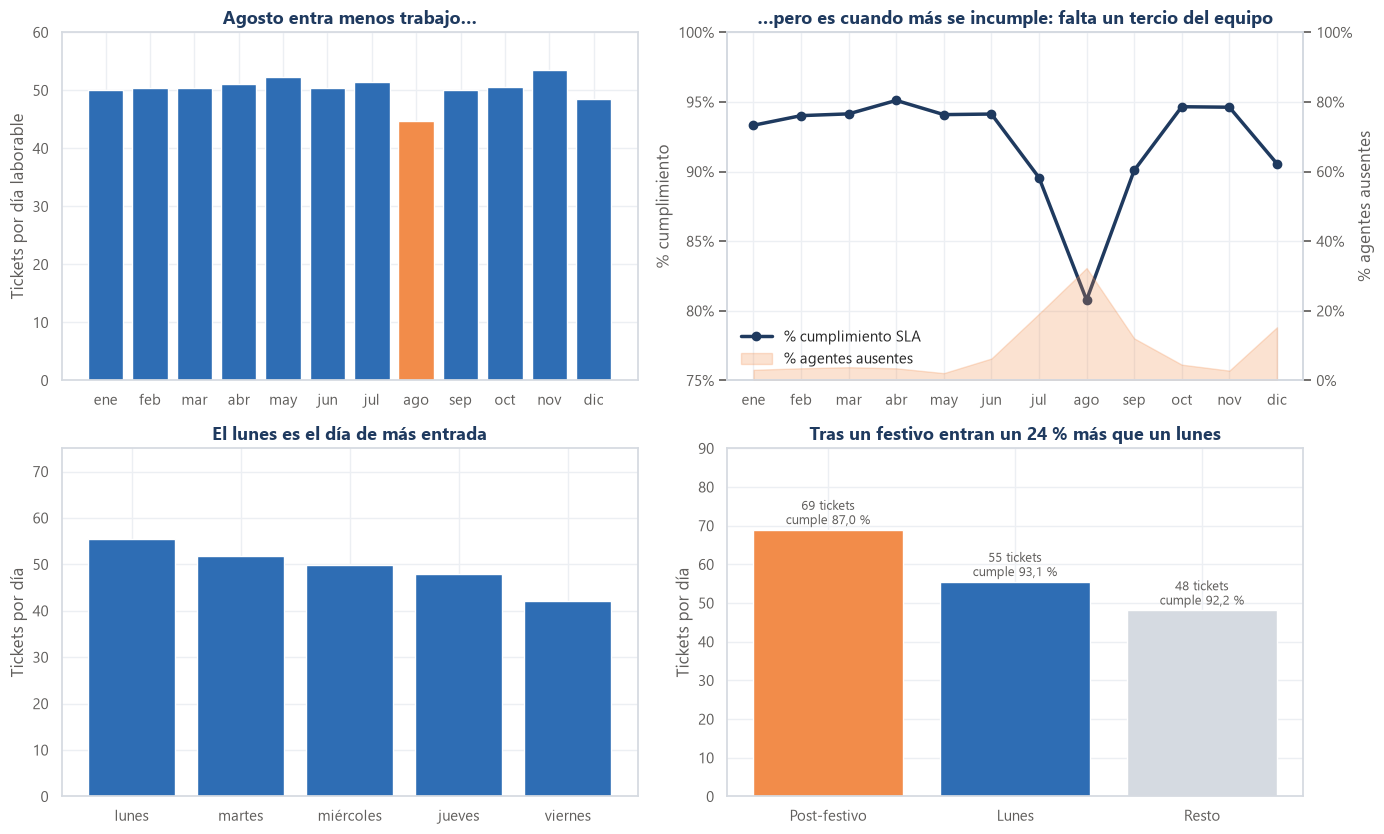

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))

# Volumen por mes
ax = axes[0, 0]
colores = [NARANJA if m == "ago" else AZUL_MEDIO for m in por_mes.index]
ax.bar(por_mes.index, por_mes.tickets_por_dia, color=colores)
ax.set(title="Agosto entra menos trabajo…", ylabel="Tickets por día laborable", ylim=(0, 60))

# Cumplimiento por mes con las ausencias
ax = axes[0, 1]
ax.plot(por_mes.index, por_mes.pct_cumplimiento, marker="o", color=AZUL, lw=2.5, label="% cumplimiento SLA")
ax.set(title="…pero es cuando más se incumple: falta un tercio del equipo", ylabel="% cumplimiento", ylim=(75, 100))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2 = ax.twinx()
ax2.fill_between(por_mes.index, por_mes.pct_ausentes, color=NARANJA, alpha=.25, label="% agentes ausentes")
ax2.set(ylim=(0, 100), ylabel="% agentes ausentes")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2.grid(False)
l1, n1 = ax.get_legend_handles_labels(); l2, n2 = ax2.get_legend_handles_labels()
ax.legend(l1 + l2, n1 + n2, loc="lower left", frameon=False)

# Día de la semana
ax = axes[1, 0]
ax.bar(por_dia.index, por_dia.values, color=AZUL_MEDIO)
ax.set(title="El lunes es el día de más entrada", ylabel="Tickets por día", ylim=(0, 75))

# Tipo de día
ax = axes[1, 1]
colores = {"Post-festivo": NARANJA, "Lunes": AZUL_MEDIO, "Resto": GRIS_CLARO}
barras = ax.bar(tipo_dia.index, tipo_dia.tickets_por_dia, color=[colores[i] for i in tipo_dia.index])
for b, (_, r) in zip(barras, tipo_dia.iterrows()):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1.5,
            f"{r.tickets_por_dia:.0f} tickets\ncumple {pct(r.pct_cumple_creados_ese_dia)}",
            ha="center", fontsize=9, color=GRIS)
ax.set(title=f"Tras un festivo entran un {pct(subida * 100, 0)} más que un lunes", ylabel="Tickets por día", ylim=(0, 90))

plt.tight_layout()
guardar(fig, "02_estacionalidad.png")
plt.show()

### Resultados y conclusiones del bloque 2

- **El volumen se mantiene relativamente estable durante el año** (~50 tickets por día laborable) y **agosto es el mes con menos
  entrada** (44,7). Aun así, **agosto es el peor mes en cumplimiento: 80,8 %**, con un 32 % del equipo
  de vacaciones. Julio (89,6 %, 19 % ausentes) y diciembre (90,6 %, 15 % ausentes) siguen el mismo
  patrón a menor escala. → El problema de agosto es de **capacidad**, no de demanda.
- **El lunes concentra la entrada** y baja hasta el viernes (55 → 42 tickets por día).
- **Tras un festivo entran un 24 % más de tickets que un lunes** (69 frente a 55 de media). Con solo
  19 días post-festivo, la prueba de Mann-Whitney da p = 3·10⁻⁵: la diferencia observada es estadísticamente significativa.
  Y los tickets que entran ese día **cumplen peor**: 87,0 % frente al 93,1 % de un lunes.

**Consideración metodológica:** en agosto coinciden las vacaciones **y** el calor. Este bloque
muestra que falta gente, pero no descarta que el calor también influya. Se separan en el bloque 4.

**Recomendación:** planificar las vacaciones para no bajar de un mínimo de agentes en agosto
(y en la segunda quincena de diciembre), y reforzar el turno el primer día laborable tras cada festivo.


## 3 · Pareto ABC

**Objetivo del análisis (pregunta 2):** ¿cuál es el balance neto bonus − penalización en €, y qué departamentos,
tipos de ticket y clientes concentran el 80 % de la penalización?

**Criterio de atribución de penalizaciones:** se calcula por cliente × sprint (la factura) y se reparte a partes
iguales entre los tickets incumplidos de ese cliente en ese sprint; cada ticket la lleva al departamento
que lo resolvió. Este reparto es un criterio analítico, no una medida directa de la responsabilidad de cada departamento.

**Clases ABC:** A = los que suman hasta el 80 % de la penalización; B = hasta el 95 %; C = el resto.
Un «80/20» clásico sería que **pocos** elementos (≈ 20 %) fueran clase A.

In [17]:
def abc(serie: pd.Series) -> pd.DataFrame:
    """Ordena de mayor a menor, calcula % y % acumulado y asigna la clase ABC
    (un elemento es A si el acumulado ANTES de él no llega al 80 %)."""
    d = serie.sort_values(ascending=False).to_frame("penalizacion_eur")
    d["pct"] = d.penalizacion_eur / d.penalizacion_eur.sum() * 100
    d["pct_acumulado"] = d.pct.cumsum()
    previo = d.pct_acumulado - d.pct
    d["clase"] = np.select([previo < 80, previo < 95], ["A", "B"], "C")
    return d

balance = cli_sprint.ajuste_eur.sum()
bonus = cli_sprint.loc[cli_sprint.ajuste_eur > 0, "ajuste_eur"].sum()
penal = -cli_sprint.loc[cli_sprint.ajuste_eur < 0, "ajuste_eur"].sum()
cuota = cli_sprint.cuota_sprint_eur.sum()
print(f"Facturado (cuota) ... {eur(cuota)}")
print(f"Bonus ............... {eur(bonus)}  ({pct(bonus / cuota * 100, 2)} de la cuota)")
print(f"Penalización ........ {eur(penal)}  ({pct(penal / cuota * 100, 2)} de la cuota)")
print(f"Balance neto ........ {eur(balance)}  ({pct(balance / cuota * 100, 2)} de la cuota)")

Facturado (cuota) ... 10.973.784 €
Bonus ............... 74.447 €  (0,68 % de la cuota)
Penalización ........ 142.513 €  (1,30 % de la cuota)
Balance neto ........ -68.066 €  (-0,62 % de la cuota)


In [18]:
# Departamento × tipo de ticket
medidos_pen = tickets[tickets.cumple_resolucion.notna()]
# las tareas no facturan (Ficha §0.2), así que no generan penalización: se dejan fuera del Pareto
dep_tipo = abc(medidos_pen.groupby(["departamento", "tipo"]).penalizacion_atribuida_eur.sum().loc[lambda s: s > 0])
n_a = (dep_tipo.clase == "A").sum()
print(f"Clase A: {n_a} de {len(dep_tipo)} combinaciones departamento × tipo ({pct(n_a / len(dep_tipo) * 100, 0)})")
dep_tipo.round(1)

Clase A: 7 de 10 combinaciones departamento × tipo (70 %)


penalizacion_eur   pct  pct_acumulado  \
departamento            tipo                                                
Service Desk N1         Incidencia           28593.1  20.1           20.1   
                        Petición             23601.3  16.6           36.6   
Soporte Aplicaciones N2 Incidencia           17632.2  12.4           49.0   
Infraestructura         Incidencia           16970.4  11.9           60.9   
Desarrollo              Incidencia           14752.2  10.4           71.3   
Infraestructura         Petición             12289.1   8.6           79.9   
Seguridad               Petición             10391.5   7.3           87.2   
Soporte Aplicaciones N2 Petición              6775.1   4.8           91.9   
Desarrollo              Petición              6374.9   4.5           96.4   
Seguridad               Incidencia            5133.2   3.6          100.0   

                                   clase  
departamento            tipo              
Service Desk N1         Incidencia     A  
                        Petición       A  
Soporte Aplicaciones N2 Incidencia     A  
Infraestructura         Incidencia     A  
Desarrollo              Incidencia     A  
Infraestructura         Petición       A  
Seguridad               Petición       A  
Soporte Aplicaciones N2 Petición       B  
Desarrollo              Petición       B  
Seguridad               Incidencia     C

In [19]:
# Tasa frente a importe por departamento: ¿quién incumple más y quién cuesta más?
dep = medidos_pen.assign(incumple=~medidos_pen.cumple_resolucion.astype(bool)).groupby("departamento").agg(
    tickets_medidos=("ticket_id", "size"),
    pct_incumplimiento=("incumple", lambda s: s.mean() * 100),
    tickets_incumplidos=("incumple", "sum"),
    penalizacion_eur=("penalizacion_atribuida_eur", "sum"))
dep["pct_de_la_penalizacion"] = dep.penalizacion_eur / dep.penalizacion_eur.sum() * 100
dep.sort_values("penalizacion_eur", ascending=False).round(1)

,tickets_medidos,pct_incumplimiento,tickets_incumplidos,penalizacion_eur,pct_de_la_penalizacion
departamento,,,,,
Service Desk N1,15965,4.3,686,52194.4,36.6
Infraestructura,3043,11.4,346,29259.5,20.5
Soporte Aplicaciones N2,2455,13.7,337,24407.3,17.1
Desarrollo,1030,32.7,337,21127.2,14.8
Seguridad,1971,10.5,206,15524.7,10.9


In [20]:
# Clientes (los dos años juntos)
pen_cliente = abc(perfil.set_index("cliente").penalizacion_eur.abs().loc[lambda s: s > 0])
nivel = perfil.set_index("cliente").nivel_contrato
pen_cliente["nivel"] = nivel.reindex(pen_cliente.index)
n_a = (pen_cliente.clase == "A").sum()
print(f"Clientes con penalización: {len(pen_cliente)} de {len(perfil)}")
print(f"Clase A: {n_a} clientes ({pct(n_a / len(pen_cliente) * 100, 0)} de los que penalizan)")
print("\nClientes de clase A por nivel:", pen_cliente[pen_cliente.clase == "A"].nivel.value_counts().to_dict())
pen_cliente.head(15).round(1)

Clientes con penalización: 22 de 40
Clase A: 14 clientes (64 % de los que penalizan)

Clientes de clase A por nivel: {'Gold': 8, 'Silver': 6}


,penalizacion_eur,pct,pct_acumulado,clase,nivel
cliente,,,,,
Clínicas Miranda S.A.,12112.1,8.5,8.5,A,Gold
Energía Huerta S.A.,11956.2,8.4,16.9,A,Gold
Consorcio Landa S.A.,11776.5,8.3,25.2,A,Gold
Energía Moles S.L.,11044.2,7.7,32.9,A,Gold
Comercial Galván S.L.,10928.9,7.7,40.6,A,Gold
Consorcio Leal S.A.,10220.7,7.2,47.7,A,Gold
Comercial Valera S.A.,8100.8,5.7,53.4,A,Gold
Clínicas Segarra S.A.,7529.8,5.3,58.7,A,Gold
Transportes Santiago S.A.,6901.2,4.8,63.6,A,Silver


Guardado: 04_analysis/outputs/03_pareto.png


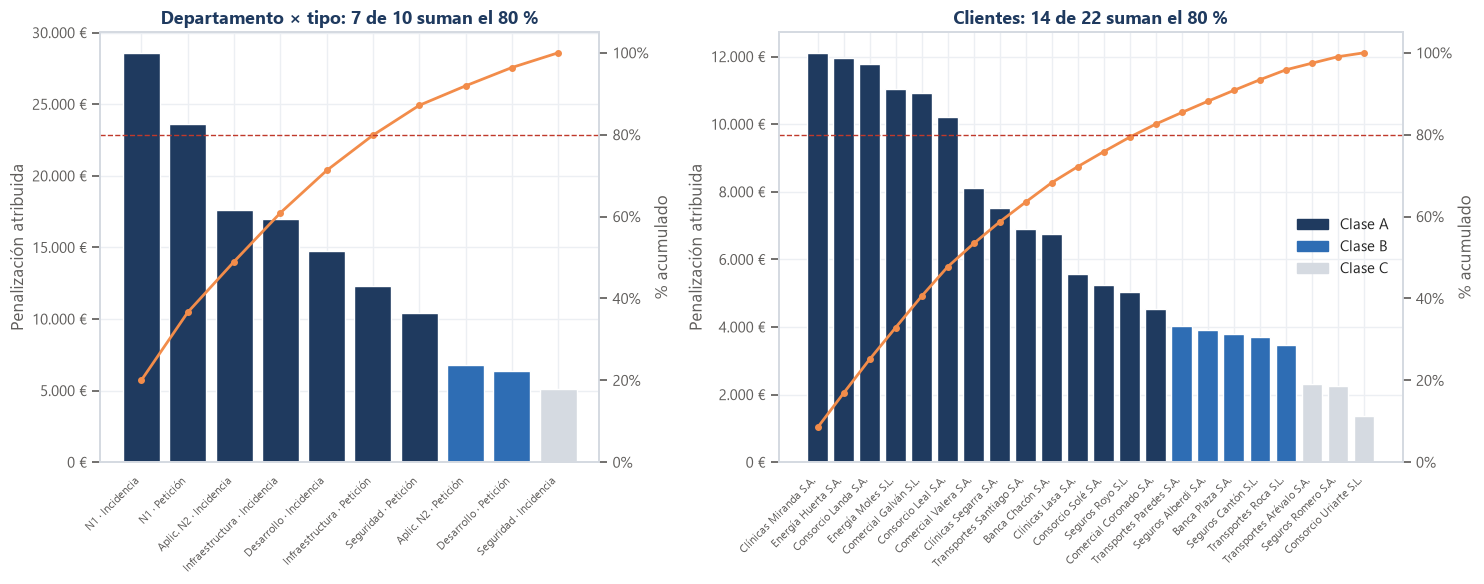

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.25]})
COLOR_ABC = {"A": AZUL, "B": AZUL_MEDIO, "C": GRIS_CLARO}

def dibujar_pareto(ax, d, etiquetas, titulo):
    x = np.arange(len(d))
    ax.bar(x, d.penalizacion_eur, color=[COLOR_ABC[c] for c in d.clase])
    ax.set_xticks(x, etiquetas, rotation=45, ha="right", fontsize=8)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: eur(v)))
    ax.set(ylabel="Penalización atribuida", title=titulo)
    ax2 = ax.twinx()
    ax2.plot(x, d.pct_acumulado, color=NARANJA, marker="o", ms=4, lw=2)
    ax2.axhline(80, color=ROJO, ls="--", lw=1)
    ax2.set(ylim=(0, 105), ylabel="% acumulado")
    ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax2.grid(False)

etq = [f"{d.split()[0] if d != 'Soporte Aplicaciones N2' else 'Aplic. N2'} · {t}"
       .replace("Service · ", "N1 · ") for d, t in dep_tipo.index]
dibujar_pareto(axes[0], dep_tipo, etq,
               f"Departamento × tipo: {(dep_tipo.clase == 'A').sum()} de {len(dep_tipo)} suman el 80 %")
dibujar_pareto(axes[1], pen_cliente, pen_cliente.index,
               f"Clientes: {(pen_cliente.clase == 'A').sum()} de {len(pen_cliente)} suman el 80 %")
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color=v, label=f"Clase {k}") for k, v in COLOR_ABC.items()],
               loc="center right", frameon=False)
plt.tight_layout()
guardar(fig, "03_pareto.png")
plt.show()

### Resultados y conclusiones del bloque 3

- **Balance de los dos años:** 10,97 M€ facturados, 74.447 € de bonus y 142.513 € de penalización →
  **−68.066 € (−0,62 % de la cuota)**. Con el tope del contrato la pérdida es contenida.
- **La penalización no sigue una distribución 80/20 estricta:** hacen falta **7 de 10** combinaciones de
  departamento × tipo y **14 de 22** clientes para llegar al 80 %. La penalización está **repartida**:
  no se arregla actuando sobre un departamento o dos clientes.
- **Los 14 clientes de la clase A son los 8 Gold y 6 Silver**: el riesgo financiero lo marca el **nivel
  de contrato** (objetivos 95 % y 90 %), más que un mal servicio concentrado.
- **La tasa de incumplimiento y el importe penalizado representan aspectos diferentes.** Service Desk N1 es el que **mejor** cumple (4,3 % de incumplimiento) y el que
  **más** penaliza (36,6 %). Desarrollo es el **peor** (32,7 %) y solo pesa el 14,8 %.


**Interpretación:** N1 concentra más penalización por su volumen de tickets, a pesar de registrar la menor tasa de incumplimiento. Los P1 representan solo 1.255 € de los 52.194 € atribuidos a N1. Para priorizar mejoras conviene analizar conjuntamente el importe económico y la tasa de incumplimiento: el primero señala dónde se concentra el impacto financiero y la segunda ayuda a identificar procesos con margen de mejora.


## 4 · Contexto externo: calor frente a vacaciones

**Objetivo del análisis (pregunta 3, segunda parte):** ¿el calor cambia el volumen de incidencias graves y el
cumplimiento? Y ¿cuánto pesan las vacaciones?

**Posible factor de confusión (Ficha §2.3):** el calor y las vacaciones caen en los mismos meses. Si comparamos días de
calor con el resto del año, los días de calor son también días con un tercio del equipo de vacaciones,
y no sabríamos cuál de las dos cosas causa el efecto. Se trata de un **factor de confusión**: ambas variables coinciden temporalmente y deben analizarse por separado.

**Metodología para aislar los efectos:**
1. **Comparar solo dentro de julio y agosto**, donde las ausencias son parecidas los días de calor y
   los de no calor. Si queda diferencia, es del calor.
2. **Un modelo mes a mes con las dos variables a la vez** (regresión): mide el efecto de cada una
   manteniendo la otra fija.

In [22]:
from scipy.stats import mannwhitneyu, pearsonr
import statsmodels.formula.api as smf

lab = dias[dias.es_laborable & (pd.to_datetime(dias.fecha) < "2026-01-01")].copy()

def comparar(sub, etiqueta):
    cal, frio = sub[sub.es_dia_caluroso], sub[~sub.es_dia_caluroso]
    cumpl = lambda s: s.cumplidos.sum() / (s.cumplidos.sum() + s.incumplidos.sum()) * 100
    p = mannwhitneyu(cal.infra_p1_p2_creados, frio.infra_p1_p2_creados, alternative="greater").pvalue
    return pd.Series({
        "días > 35 °C": len(cal), "días ≤ 35 °C": len(frio),
        "% ausentes > 35 °C": cal.pct_agentes_ausentes.mean(), "% ausentes ≤ 35 °C": frio.pct_agentes_ausentes.mean(),
        "Infra P1/P2 por día > 35 °C": cal.infra_p1_p2_creados.mean(),
        "Infra P1/P2 por día ≤ 35 °C": frio.infra_p1_p2_creados.mean(),
        "p (Mann-Whitney, Infra)": p,
        "% cumplimiento > 35 °C": cumpl(cal), "% cumplimiento ≤ 35 °C": cumpl(frio),
    }, name=etiqueta)

calor = pd.concat([comparar(lab, "Todo el año (con confusión)"),
                   comparar(lab[lab.mes.isin([7, 8])], "Solo julio y agosto")], axis=1)
calor.round(3)

,Todo el año (con confusión),Solo julio y agosto
días > 35 °C,60.000,47.000
días ≤ 35 °C,440.000,38.000
% ausentes > 35 °C,21.488,25.438
% ausentes ≤ 35 °C,7.403,25.555
Infra P1/P2 por día > 35 °C,1.000,1.128
Infra P1/P2 por día ≤ 35 °C,0.552,0.553
"p (Mann-Whitney, Infra)",0.000,0.003
% cumplimiento > 35 °C,87.549,85.701
% cumplimiento ≤ 35 °C,92.818,85.262


In [23]:
# Mes a mes: ¿qué explica el cumplimiento, las ausencias o el calor?
lab["anio_mes"] = pd.to_datetime(lab.fecha).dt.to_period("M")
meses = lab.groupby("anio_mes").agg(cumplidos=("cumplidos", "sum"), incumplidos=("incumplidos", "sum"),
                                    ausentes=("pct_agentes_ausentes", "mean"),
                                    dias_calor=("es_dia_caluroso", "mean"))
meses["cumplimiento"] = meses.cumplidos / (meses.cumplidos + meses.incumplidos) * 100
meses["dias_calor"] *= 100

r_aus, p_aus = pearsonr(meses.ausentes, meses.cumplimiento)
r_cal, p_cal = pearsonr(meses.dias_calor, meses.cumplimiento)
print("Correlaciones simples (cada variable por separado, 24 meses):")
print(f"  % ausentes   ↔ cumplimiento: r = {r_aus:.2f}  (p = {p_aus:.1g})")
print(f"  % días calor ↔ cumplimiento: r = {r_cal:.2f}  (p = {p_cal:.1g})")

modelo = smf.ols("cumplimiento ~ ausentes + dias_calor", data=meses).fit()
print("\nRegresión con las dos a la vez (R² = %.2f):" % modelo.rsquared)
pd.DataFrame({"efecto (puntos de cumplimiento por punto)": modelo.params,
              "p-valor": modelo.pvalues}).drop("Intercept").round(3)

Correlaciones simples (cada variable por separado, 24 meses):
  % ausentes   ↔ cumplimiento: r = -0.92  (p = 3e-10)
  % días calor ↔ cumplimiento: r = -0.67  (p = 0.0003)

Regresión con las dos a la vez (R² = 0.85):


,efecto (puntos de cumplimiento por punto),p-valor
ausentes,-0.478,0.000
dias_calor,0.027,0.314


Guardado: 04_analysis/outputs/04_contexto_externo.png


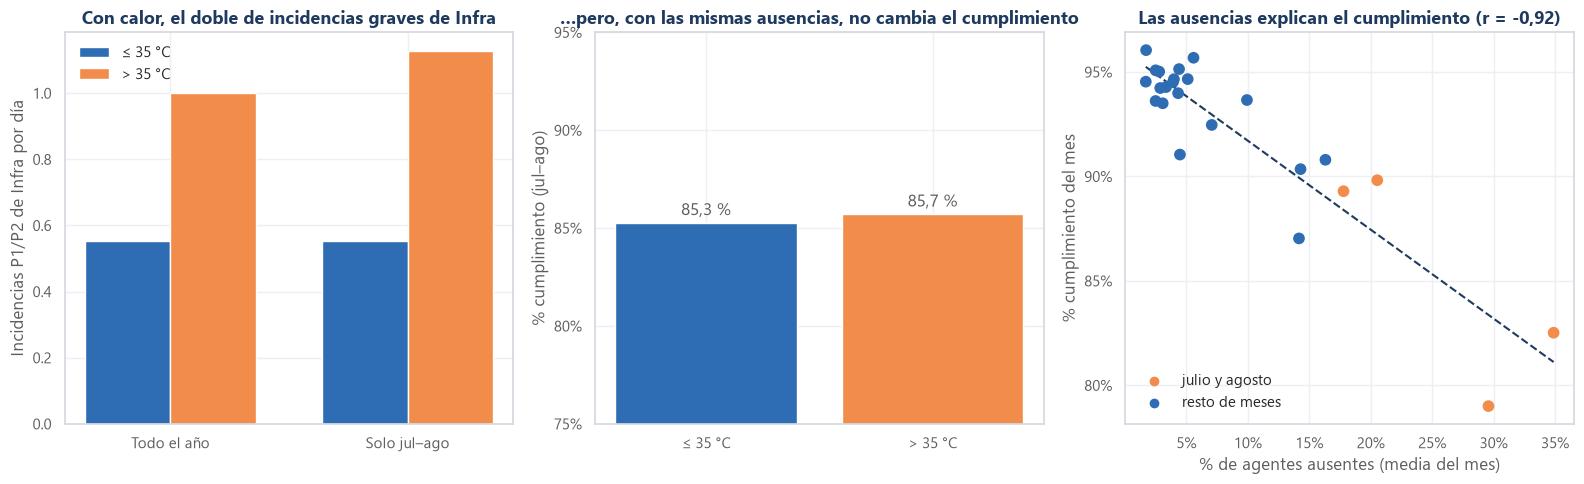

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Incidencias graves de Infraestructura: todo el año frente a solo julio-agosto
ax = axes[0]
x = np.arange(2)
ancho = 0.36
ax.bar(x - ancho / 2, calor.loc["Infra P1/P2 por día ≤ 35 °C"], ancho, color=AZUL_MEDIO, label="≤ 35 °C")
ax.bar(x + ancho / 2, calor.loc["Infra P1/P2 por día > 35 °C"], ancho, color=NARANJA, label="> 35 °C")
ax.set_xticks(x, ["Todo el año", "Solo jul–ago"])
ax.set(ylabel="Incidencias P1/P2 de Infra por día",
       title="Con calor, el doble de incidencias graves de Infra")
ax.legend(frameon=False)

# 2. Cumplimiento dentro de julio-agosto: el calor no lo mueve
ax = axes[1]
vals = [calor.loc["% cumplimiento ≤ 35 °C", "Solo julio y agosto"], calor.loc["% cumplimiento > 35 °C", "Solo julio y agosto"]]
b = ax.bar(["≤ 35 °C", "> 35 °C"], vals, color=[AZUL_MEDIO, NARANJA])
for barra, v in zip(b, vals):
    ax.text(barra.get_x() + barra.get_width() / 2, v + 0.4, pct(v), ha="center", color=GRIS)
ax.set(ylim=(75, 95), ylabel="% cumplimiento (jul–ago)",
       title="…pero, con las mismas ausencias, no cambia el cumplimiento")
ax.yaxis.set_major_locator(mtick.MultipleLocator(5))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))

# 3. Mes a mes: ausencias frente a cumplimiento
ax = axes[2]
color_mes = [NARANJA if p.month in (7, 8) else AZUL_MEDIO for p in meses.index]
ax.scatter(meses.ausentes, meses.cumplimiento, c=color_mes, s=55, zorder=3)
z = np.polyfit(meses.ausentes, meses.cumplimiento, 1)
xs = np.linspace(meses.ausentes.min(), meses.ausentes.max(), 50)
ax.plot(xs, np.polyval(z, xs), color=AZUL, lw=1.5, ls="--")
ax.set(xlabel="% de agentes ausentes (media del mes)", ylabel="% cumplimiento del mes",
       title=f"Las ausencias explican el cumplimiento (r = {r_aus:.2f})".replace(".", ","))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.yaxis.set_major_locator(mtick.MultipleLocator(5))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.scatter([], [], c=NARANJA, label="julio y agosto"); ax.scatter([], [], c=AZUL_MEDIO, label="resto de meses")
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
guardar(fig, "04_contexto_externo.png")
plt.show()

### Resultados y conclusiones del bloque 4

- **En el conjunto del año, el calor se asocia con un menor cumplimiento:** los días de más de 35 °C cumplen 87,5 % frente al
  92,8 %. Pero esos días tienen un **21,5 % de ausentes frente al 7,4 %**: estamos comparando verano con
  invierno, no calor con no calor. Es la **variable de confusión** que avisaba la Ficha.
- **Dentro de julio y agosto** (ausencias iguales: 25,4 % y 25,6 %):
  - el calor **sí duplica las incidencias graves de Infraestructura** (1,13 frente a 0,55 por día,
    p = 0,003): el efecto que se inyectó (refrigeración del CPD, cortes eléctricos) se detecta;
  - pero **el cumplimiento no cambia** (85,7 % frente a 85,3 %).
- **Mes a mes, las vacaciones lo explican casi todo:** r = −0,92 entre % de ausentes y cumplimiento.
  El calor solo, r = −0,67, parece importante, pero en la regresión con las dos variables a la vez
  (R² = 0,85) **cada punto de ausencias resta 0,48 puntos de cumplimiento (p < 0,001)** y el calor
  **no tiene efecto propio (p = 0,31)**: la asociación inicial estaba condicionada por las ausencias.

**Conclusión:** la disponibilidad de personal presenta una relación más clara con el cumplimiento del SLA que la temperatura. El calor genera más
trabajo para Infraestructura (incidencias graves), pero el equipo lo absorbe sin perder SLA.

**Recomendación:**
- Planificar las vacaciones para no bajar de un mínimo de agentes disponibles (es la palanca del SLA).
- Guardia de Infraestructura los días con previsión de más de 35 °C: no por el SLA, sino porque se
  duplican las incidencias graves (impacto en el cliente).


**Interpretación:** la comparación restringida a julio y agosto permite controlar mejor las diferencias en disponibilidad de personal. Los resultados relacionan el calor con un mayor número de incidencias graves de Infraestructura, pero no muestran un efecto adicional claro sobre el cumplimiento del SLA.


## 5 · Perfiles de cliente (K-Means)

**Objetivo del análisis (pregunta 6):** ¿qué perfiles de cliente hay según su patrón de tickets, y hay contratos
cuyo nivel no se ajusta al uso real?

**Criterio para la segmentación:** agrupamos a los clientes solo por **cómo usan el servicio**
(tamaño, tickets por usuario, % de P1, % escalados, % de incumplimiento), **sin** la penalización ni el
nivel de contrato. Si metiéramos la penalización, el resultado estaría condicionado por el nivel de contrato
(Bronze nunca penaliza por contrato) y no permitiría evaluar los perfiles de forma independiente. Así podemos comparar después **perfil de uso**
frente a **contrato** y ver quién no encaja.

**K-Means** agrupa clientes parecidos. Hay que elegir cuántos grupos (*k*):
- **Codo:** cuánto baja la dispersión dentro de los grupos al añadir uno más; se busca donde deja de bajar mucho.
- **Silueta:** de −1 a 1, cuánto se parece cada cliente a su grupo frente al grupo vecino.
  Por encima de 0,5 hay grupos claros; entre 0,25 y 0,5, estructura **débil**.

In [25]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cli = perfil.copy()
cli["log10_usuarios"] = np.log10(cli.n_usuarios)                 # el tamaño va de 41 a 2.967 usuarios
cli["tickets_mes_por_100_usuarios"] = cli.tickets_mes / cli.n_usuarios * 100
cli["pen_pct_cuota"] = cli.penalizacion_eur.abs() / (cli.cuota_anual_eur * cli.meses_activo / 12) * 100
VARIABLES = ["log10_usuarios", "tickets_mes_por_100_usuarios", "pct_p1", "pct_escalados", "pct_incumplimiento"]

Z = StandardScaler().fit_transform(cli[VARIABLES])   # misma escala para todas (si no, manda el tamaño)
eleccion = pd.DataFrame([
    {"k": k, "inercia": (km := KMeans(k, n_init=20, random_state=42).fit(Z)).inertia_,
     "silueta": silhouette_score(Z, km.labels_)} for k in range(2, 7)]).set_index("k")
eleccion.round(3)

,inercia,silueta
k,,
2,138.434,0.353
3,101.971,0.326
4,81.922,0.274
5,67.226,0.274
6,58.030,0.223


In [26]:
K = 3   # ver la lectura: el codo se dobla en 3 y la silueta de 3 (0,33) es casi la de 2 (0,35), pero se interpreta mejor
km = KMeans(K, n_init=20, random_state=42).fit(Z)
cli["grupo"] = km.labels_

perfil_grupos = cli.groupby("grupo").agg(
    clientes=("cliente", "size"), usuarios_medios=("n_usuarios", "mean"),
    tickets_mes_100u=("tickets_mes_por_100_usuarios", "mean"), pct_p1=("pct_p1", "mean"),
    pct_escalados=("pct_escalados", "mean"), pct_incumplimiento=("pct_incumplimiento", "mean"),
    penalizacion_pct_cuota=("pen_pct_cuota", "mean"))
orden = perfil_grupos.usuarios_medios.sort_values(ascending=False).index
NOMBRES = dict(zip(orden, ["Mayores, cumplen mejor", "Medianos, cumplen peor", "Pequeños con muchos P1"]))
cli["perfil"] = cli.grupo.map(NOMBRES)
perfil_grupos = perfil_grupos.rename(index=NOMBRES).loc[list(NOMBRES.values())]
display(perfil_grupos.round(2))
pd.crosstab(cli.perfil, cli.nivel_contrato).loc[list(NOMBRES.values()), ["Gold", "Silver", "Bronze"]]

,clientes,usuarios_medios,tickets_mes_100u,pct_p1,pct_escalados,pct_incumplimiento,penalizacion_pct_cuota
grupo,,,,,,,
"Mayores, cumplen mejor",26,917.35,4.24,1.60,33.71,8.74,1.11
"Medianos, cumplen peor",9,191.56,3.87,1.13,32.86,15.21,0.27
Pequeños con muchos P1,5,59.60,4.20,4.15,39.48,17.80,0.00


nivel_contrato,Gold,Silver,Bronze
perfil,,,
"Mayores, cumplen mejor",8,13,5
"Medianos, cumplen peor",0,1,8
Pequeños con muchos P1,0,0,5


In [27]:
# ¿Quién no encaja? Clientes Bronze que caen en el grupo de los Gold y Silver
print("Usuarios por nivel (mín · mediana · máx):")
print(cli.groupby("nivel_contrato").n_usuarios.agg(["min", "median", "max"]).to_string())
no_encajan = cli[(cli.perfil == "Mayores, cumplen mejor") & (cli.nivel_contrato == "Bronze")]
no_encajan[["cliente", "sector", "n_usuarios", "tickets", "pct_p1", "pct_escalados", "pct_incumplimiento",
            "cuota_anual_eur"]].sort_values("n_usuarios", ascending=False)

Usuarios por nivel (mín · mediana · máx):
                min  median   max
nivel_contrato                   
Bronze           41   155.5   238
Gold            878  1661.0  2967
Silver          200   530.0   852


,cliente,sector,n_usuarios,tickets,pct_p1,pct_escalados,pct_incumplimiento,cuota_anual_eur
36,Consorcio Bermúdez S.L.,Administración pública,238,265,1.51,26.4,13.6,48000.0
34,Energía Meléndez S.L.,Energía,196,52,0.00,30.8,10.0,42000.0
24,Consorcio Camino S.A.,Administración pública,175,177,1.69,36.7,10.9,30000.0
29,Transportes Cuéllar S.L.,Logística,159,130,2.31,29.2,13.4,66000.0
28,Banca Pereira S.L.,Banca,152,158,1.27,34.8,9.8,24000.0


Guardado: 04_analysis/outputs/05_clusters.png


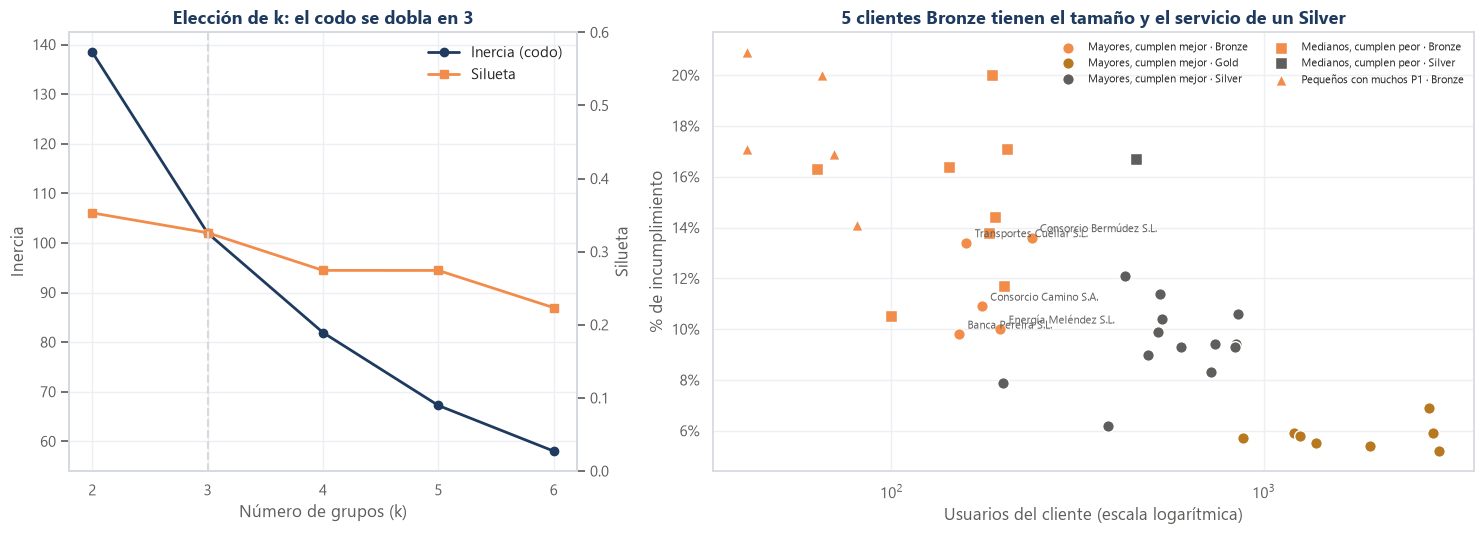

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [0.8, 1.2]})

ax = axes[0]
ax.plot(eleccion.index, eleccion.inercia, marker="o", color=AZUL, lw=2, label="Inercia (codo)")
ax.set(xlabel="Número de grupos (k)", ylabel="Inercia", title="Elección de k: el codo se dobla en 3")
ax.set_xticks(eleccion.index)
ax2 = ax.twinx()
ax2.plot(eleccion.index, eleccion.silueta, marker="s", color=NARANJA, lw=2, label="Silueta")
ax2.axvline(K, color=GRIS_CLARO, ls="--")
ax2.set(ylabel="Silueta", ylim=(0, 0.6)); ax2.grid(False)
l1, n1 = ax.get_legend_handles_labels(); l2, n2 = ax2.get_legend_handles_labels()
ax.legend(l1 + l2, n1 + n2, frameon=False, loc="upper right")

ax = axes[1]
COLOR_NIVEL = {"Gold": "#B7791F", "Silver": GRIS, "Bronze": NARANJA}
MARCA = {"Mayores, cumplen mejor": "o", "Medianos, cumplen peor": "s", "Pequeños con muchos P1": "^"}
for (perf, niv), g in cli.groupby(["perfil", "nivel_contrato"]):
    ax.scatter(g.n_usuarios, g.pct_incumplimiento, s=70, marker=MARCA[perf], color=COLOR_NIVEL[niv],
               edgecolor="white", label=f"{perf} · {niv}")
for _, r in no_encajan.iterrows():
    ax.annotate(r.cliente, (r.n_usuarios, r.pct_incumplimiento), xytext=(6, 4), textcoords="offset points",
                fontsize=8, color=GRIS)
ax.set_xscale("log")
ax.set(xlabel="Usuarios del cliente (escala logarítmica)", ylabel="% de incumplimiento",
       title=f"{len(no_encajan)} clientes Bronze tienen el tamaño y el servicio de un Silver")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend(frameon=False, fontsize=8, loc="upper right", ncol=2)
plt.tight_layout()
guardar(fig, "05_clusters.png")
plt.show()

### Resultados y conclusiones del bloque 5

- **Elección de k:** el codo se dobla en 3 y la silueta de k = 3 (0,33) es casi la de k = 2 (0,35).
  Se eligen 3 grupos porque se interpretan mejor, sabiendo que la **estructura es débil** (silueta por
  debajo de 0,5): los perfiles existen, pero los clientes no están en grupos muy separados.
- **Tres perfiles de uso:**
  - **Mayores, cumplen mejor** (26 clientes: los 8 Gold, 13 de 14 Silver y 5 Bronze): 8,7 % de
    incumplimiento.
  - **Medianos, cumplen peor** (9: 8 Bronze y 1 Silver): 15,2 %.
  - **Pequeños con muchos P1** (5 Bronze): 4,2 % de P1, más del doble que el resto, y 17,8 % de
    incumplimiento.
- **El volumen por usuario es casi igual en todos** (~4 tickets al mes por cada 100 usuarios): el
  generador reparte los tickets en proporción a los usuarios, así que esta variable no distingue perfiles
  (límite de los datos sintéticos, se dice así).
- **Posible desajuste entre uso y contrato:** **5 clientes Bronze tienen el tamaño y el servicio de un
  Silver** (152–238 usuarios, cuando un Silver empieza en 200; incumplimiento del 10–14 %, como los Silver).
  Reciben un servicio de Silver pagando Bronze y sin compromiso de SLA.

**Recomendación:** proponer a esos 5 clientes pasar a Silver (más cuota y un SLA acorde al uso
real); y revisar los «pequeños con muchos P1»: o son urgencias reales que justifican otro contrato, o se
está clasificando mal la prioridad.


## 6 · Previsión: volumen del próximo trimestre y agentes para agosto

**Objetivo del análisis (pregunta 4):** ¿cuántos tickets entrarán el próximo trimestre y cuántos agentes harán
falta en agosto para no caer de tramo?

**Prophet** (Meta) descompone una serie en **tendencia + estacionalidad semanal + estacionalidad anual
+ efectos de días especiales** y proyecta hacia delante con un **intervalo de confianza del 95 %**.

Tres decisiones:
- Se modelan solo los **días laborables** (los fines de semana casi no entran tickets y distorsionarían).
- Los **post-festivos** entran como «días especiales», para que el modelo aprenda su pico.
- **Antes de fiarnos, lo validamos:** entrenamos con 2024 y el primer semestre de 2025, predecimos el
  segundo semestre de 2025 (que ya conocemos) y medimos el error.

In [29]:
import logging
logging.getLogger("prophet.plot").setLevel(logging.CRITICAL)   # «Importing plotly failed»: no usamos gráficos interactivos
from prophet import Prophet
import cmdstanpy
cmdstanpy.disable_logging()                                      # «Chain [1] start/done processing»
logging.getLogger("prophet").setLevel(logging.CRITICAL)          # aviso de estacionalidad anual (ver la nota de abajo)
# Prophet avisa de que con menos de 730 días la estacionalidad anual puede ser inestable: tenemos ~500
# laborables en 2 años. Se mantiene (agosto y diciembre son clave), sabiendo que es una limitación.

serie = dias[dias.es_laborable].copy()
serie["ds"] = pd.to_datetime(serie.fecha)
serie = serie[serie.ds < "2026-01-01"][["ds", "tickets_creados", "es_post_festivo"]].rename(columns={"tickets_creados": "y"})
post_festivos = pd.DataFrame({"holiday": "post_festivo", "ds": serie.loc[serie.es_post_festivo, "ds"]})

def modelo():
    return Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False,
                   holidays=post_festivos, interval_width=0.95)

# Validación: entrenar hasta junio de 2025 y predecir julio–diciembre de 2025
corte = pd.Timestamp("2025-07-01")
m_val = modelo().fit(serie[serie.ds < corte])
real = serie[serie.ds >= corte]
pred = m_val.predict(real[["ds"]]).set_index("ds")
error = (real.set_index("ds").y - pred.yhat)
mape = (error.abs() / real.set_index("ds").y).mean() * 100
cobertura = ((real.set_index("ds").y >= pred.yhat_lower) & (real.set_index("ds").y <= pred.yhat_upper)).mean() * 100
print(f"Validación jul–dic 2025: error medio absoluto {error.abs().mean():.1f} tickets/día "
      f"(MAPE {pct(mape)}); el {pct(cobertura, 0)} de los días cae dentro del intervalo del 95 %")
mensual = pd.DataFrame({"real": real.set_index("ds").y, "previsto": pred.yhat}).resample("ME").sum().round(0)
mensual.index = mensual.index.strftime("%Y-%m")
mensual

Validación jul–dic 2025: error medio absoluto 5.9 tickets/día (MAPE 11,6 %); el 93 % de los días cae dentro del intervalo del 95 %


,real,previsto
ds,,
2025-07,1187,1108.0
2025-08,912,944.0
2025-09,1152,1095.0
2025-10,1200,1167.0
2025-11,1041,1034.0
2025-12,1010,1078.0


In [30]:
# Modelo final con los dos años y previsión del primer trimestre de 2026 (y agosto, para la plantilla)
m = modelo().fit(serie)
futuro = pd.DataFrame({"ds": pd.bdate_range("2026-01-02", "2026-08-31")})   # solo lunes a viernes
prev = m.predict(futuro)
prev["mes"] = prev.ds.dt.to_period("M").astype(str)

trimestre = prev[prev.ds < "2026-04-01"].groupby("mes").agg(
    dias_laborables=("yhat", "size"), tickets=("yhat", "sum"),
    minimo_95=("yhat_lower", "sum"), maximo_95=("yhat_upper", "sum")).round(0)
trimestre.loc["Total T1 2026"] = trimestre.sum()
print("Aviso: los festivos de 2026 no están en los datos (el calendario acaba el 2026-01-02), así que la")
print("previsión trata todos los lunes a viernes como laborables y no incluye los picos post-festivo de 2026.")
trimestre

Aviso: los festivos de 2026 no están en los datos (el calendario acaba el 2026-01-02), así que la
previsión trata todos los lunes a viernes como laborables y no incluye los picos post-festivo de 2026.


,dias_laborables,tickets,minimo_95,maximo_95
mes,,,,
2026-01,21.0,1111.0,820.0,1400.0
2026-02,20.0,1088.0,809.0,1366.0
2026-03,22.0,1201.0,897.0,1504.0
Total T1 2026,63.0,3400.0,2526.0,4270.0


### Agentes necesarios en agosto

Pasamos de tickets a personas con la **carga por agente disponible**: tickets que entran cada día ÷
agentes que no están de vacaciones ni de baja. Mes a mes, la carga explica bien el cumplimiento:
buscamos la carga máxima que mantiene el cumplimiento en el objetivo, y con la previsión de agosto
calculamos cuántos agentes tienen que estar disponibles.

In [31]:
lab_m = dias[dias.es_laborable & (pd.to_datetime(dias.fecha) < "2026-01-01")].copy()
lab_m["disponibles"] = lab_m.agentes_activos - lab_m.agentes_ausentes
lab_m["carga"] = lab_m.tickets_creados / lab_m.disponibles
lab_m["anio_mes"] = pd.to_datetime(lab_m.fecha).dt.to_period("M")
carga_mes = lab_m.groupby("anio_mes").agg(carga=("carga", "mean"), disponibles=("disponibles", "mean"),
                                          plantilla=("agentes_activos", "mean"),
                                          cumplidos=("cumplidos", "sum"), incumplidos=("incumplidos", "sum"))
carga_mes["cumplimiento"] = carga_mes.cumplidos / (carga_mes.cumplidos + carga_mes.incumplidos) * 100

ajuste = smf.ols("cumplimiento ~ carga", data=carga_mes).fit()
OBJETIVO_SERVICIO = 93.0     # % de cumplimiento global que se quiere sostener (ver la lectura)
carga_max = (OBJETIVO_SERVICIO - ajuste.params.Intercept) / ajuste.params.carga
tickets_agosto = prev.loc[prev.mes == "2026-08", "yhat"].mean()
plantilla = carga_mes.plantilla.iloc[-1]
necesarios = np.ceil(tickets_agosto / carga_max)
ago25 = carga_mes.loc[pd.Period("2025-08")]

print(f"Cumplimiento = {ajuste.params.Intercept:.1f} {ajuste.params.carga:+.1f} × carga  (R² = {ajuste.rsquared:.2f})")
print(f"Carga máxima para sostener un {pct(OBJETIVO_SERVICIO, 0)}: {carga_max:.2f} tickets por agente disponible y día")
print(f"\nAgosto 2026, previsión: {tickets_agosto:.1f} tickets por día laborable")
print(f"Agentes disponibles necesarios: {necesarios:.0f} de una plantilla de {plantilla:.0f}")
print(f"→ como máximo {plantilla - necesarios:.0f} agentes de vacaciones a la vez "
      f"(en agosto de 2025 hubo de media {ago25.plantilla - ago25.disponibles:.1f} fuera y se cumplió el {pct(ago25.cumplimiento)})")

# Sensibilidad: según el cumplimiento que se quiera sostener
sens = pd.DataFrame({"objetivo_%": [90, 91, 92, 93, 94]})
sens["carga_max"] = (sens["objetivo_%"] - ajuste.params.Intercept) / ajuste.params.carga
sens["agentes_disponibles"] = np.ceil(tickets_agosto / sens.carga_max).astype(int)
sens["max_de_vacaciones_a_la_vez"] = (plantilla - sens.agentes_disponibles).astype(int)
sens.round(2)

Cumplimiento = 128.4 -22.1 × carga  (R² = 0.67)
Carga máxima para sostener un 93 %: 1.60 tickets por agente disponible y día

Agosto 2026, previsión: 49.3 tickets por día laborable
Agentes disponibles necesarios: 31 de una plantilla de 35
→ como máximo 4 agentes de vacaciones a la vez (en agosto de 2025 hubo de media 10.4 fuera y se cumplió el 79,0 %)


,objetivo_%,carga_max,agentes_disponibles,max_de_vacaciones_a_la_vez
0,90,1.74,29,6
1,91,1.69,30,5
2,92,1.65,30,5
3,93,1.60,31,4
4,94,1.56,32,3


Guardado: 04_analysis/outputs/06_forecast.png


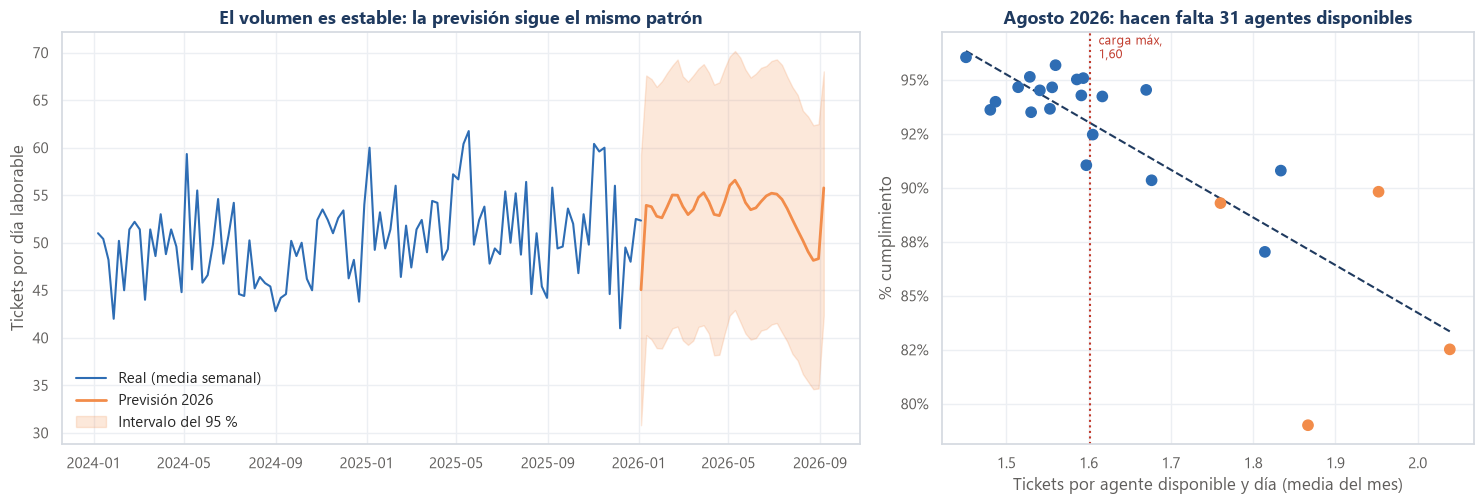

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.5, 1]})

ax = axes[0]
hist = serie.set_index("ds").y.resample("W").mean()
fut = prev.set_index("ds")[["yhat", "yhat_lower", "yhat_upper"]].resample("W").mean()
ax.plot(hist.index, hist, color=AZUL_MEDIO, lw=1.5, label="Real (media semanal)")
ax.plot(fut.index, fut.yhat, color=NARANJA, lw=2, label="Previsión 2026")
ax.fill_between(fut.index, fut.yhat_lower, fut.yhat_upper, color=NARANJA, alpha=.2, label="Intervalo del 95 %")
ax.set(ylabel="Tickets por día laborable", title="El volumen es estable: la previsión sigue el mismo patrón")
ax.legend(frameon=False, loc="lower left")

ax = axes[1]
col = [NARANJA if p.month in (7, 8) else AZUL_MEDIO for p in carga_mes.index]
ax.scatter(carga_mes.carga, carga_mes.cumplimiento, c=col, s=55, zorder=3)
xs = np.linspace(carga_mes.carga.min(), carga_mes.carga.max(), 50)
ax.plot(xs, ajuste.params.Intercept + ajuste.params.carga * xs, color=AZUL, ls="--", lw=1.5)
ax.axvline(carga_max, color=ROJO, ls=":", lw=1.5)
ax.text(carga_max + 0.01, 96, f"carga máx.\n{carga_max:.2f}".replace(".", ","), color=ROJO, fontsize=9)
ax.set(xlabel="Tickets por agente disponible y día (media del mes)", ylabel="% cumplimiento",
       title=f"Agosto 2026: hacen falta {necesarios:.0f} agentes disponibles")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
plt.tight_layout()
guardar(fig, "06_forecast.png")
plt.show()

### Resultados y conclusiones del bloque 6

- **Validación del modelo:** entrenado hasta junio de 2025, el modelo predijo julio–diciembre con un
  error medio de **6 tickets por día (MAPE 11,6 %)** y el 91 % de los días cayó dentro del intervalo del
  95 % (lo esperable sería ~95 %: el intervalo es algo estrecho). A nivel de mes el error es pequeño
  (agosto 2025: 944 previstos frente a 912 reales).
- **Primer trimestre de 2026: ~3.400 tickets** (entre 2.520 y 4.276 con un 95 % de confianza), unos
  1.100–1.200 al mes. El volumen es estable, sin tendencia fuerte.
- **Estimación de necesidades de personal:** mes a mes, el cumplimiento cae ~2,2 puntos por cada 0,1 tickets más por agente
  disponible y día (R² = 0,67). Para sostener un **93 %**, la carga no debe pasar de **1,60**.
- **Agosto 2026:** con ~49 tickets por día laborable hacen falta **31 agentes disponibles de 35 → como
  máximo 4 de vacaciones a la vez**. En agosto de 2025 hubo 10,4 fuera de media y se cumplió el 79 %.
  La tabla de sensibilidad da la regla para negociar: entre 3 (para un 94 %) y 6 (para un 90 %).

**Limitaciones:** solo 2 años de historia (Prophet avisa de que la estacionalidad anual puede
ser inestable); los festivos de 2026 no están en los datos; y la relación carga → cumplimiento es una
correlación mensual (24 puntos), no un experimento.

**Recomendación:** fijar en la política de vacaciones un **máximo de 4 agentes fuera a la vez en
agosto** (o contratar refuerzo temporal si se quieren dar más), y revisar el cupo cada año con la previsión.


**Criterio de validación:** el modelo se ha evaluado sobre un periodo posterior al utilizado para entrenarlo. Esta separación ayuda a estimar su capacidad de generalización y reduce el riesgo de interpretar un buen ajuste histórico como garantía de precisión futura.


## 7 · Riesgo de incumplir (regresión logística)

**Objetivo del análisis (pregunta 5):** ¿qué tickets abiertos tienen más probabilidad de incumplir y cuánta
penalización evitaría resolverlos a tiempo?

La **regresión logística** estima la probabilidad (0–1) de que un ticket incumpla a partir de sus
características. Sus coeficientes se leen como **odds ratio**: un 2 significa que esa característica
**duplica las probabilidades** de incumplir; un 0,5, que las reduce a la mitad.

**Selección de variables: solo información disponible mientras el ticket permanece abierto** (tipo, prioridad,
cliente, departamento, agente, reasignaciones hasta el momento, día de entrada, ausencias de ese día).
Nada que dependa del final, como los minutos totales consumidos: esto introduciría **fuga de información** y sobreestimaría el rendimiento del modelo en producción.

**Validación:** entrenamos con 2024 y medimos con 2025. **AUC** = probabilidad de que, cogiendo al azar
un ticket que incumplió y otro que cumplió, el modelo dé más riesgo al que incumplió
(0,5 equivale a una clasificación aleatoria y 1 indica discriminación perfecta).

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve

ausencias_dia = dias[["fecha", "pct_agentes_ausentes"]]
base = tickets.merge(ausencias_dia, on="fecha", how="left")

CATEGORICAS = ["tipo", "prioridad", "nivel_contrato", "departamento", "seniority"]
NUMERICAS = ["n_reasignaciones", "es_post_festivo", "es_dia_caluroso", "pct_agentes_ausentes"]

def preparar(df, columnas=None):
    X = pd.get_dummies(df[CATEGORICAS].fillna("sin asignar"), drop_first=True, dtype=float)
    for c in NUMERICAS:
        X[c] = df[c].astype(float)
    return X if columnas is None else X.reindex(columns=columnas, fill_value=0.0)

medidos7 = base[base.cumple_resolucion.notna()].copy()
medidos7["incumple"] = (~medidos7.cumple_resolucion.astype(bool)).astype(int)
X = preparar(medidos7)
entreno, prueba = medidos7.anio == 2024, medidos7.anio == 2025

logit = LogisticRegression(max_iter=3000).fit(X[entreno], medidos7.incumple[entreno])
p_prueba = logit.predict_proba(X[prueba])[:, 1]
auc = roc_auc_score(medidos7.incumple[prueba], p_prueba)
print(f"Entrenado con {entreno.sum():,} tickets de 2024; probado con {prueba.sum():,} de 2025".replace(",", "."))
print(f"AUC en 2025: {auc:.2f}  (tasa real de incumplimiento en 2025: {pct(medidos7.incumple[prueba].mean() * 100)})")

# ¿Sirve para priorizar? Si revisamos el 10 % de tickets con más riesgo, ¿qué parte de los incumplidos cazamos?
orden = np.argsort(-p_prueba)
top10 = orden[: int(len(orden) * 0.10)]
cazados = medidos7.incumple[prueba].to_numpy()[top10].sum() / medidos7.incumple[prueba].sum()
print(f"El 10 % de tickets con más riesgo contiene el {pct(cazados * 100)} de los incumplimientos de 2025")

Entrenado con 11.964 tickets de 2024; probado con 12.492 de 2025
AUC en 2025: 0.80  (tasa real de incumplimiento en 2025: 8,1 %)
El 10 % de tickets con más riesgo contiene el 44,5 % de los incumplimientos de 2025


In [34]:
odds = pd.Series(np.exp(logit.coef_[0]), index=X.columns, name="odds_ratio").sort_values()
odds.round(2).to_frame()

,odds_ratio
nivel_contrato_Gold,0.29
seniority_senior,0.54
nivel_contrato_Silver,0.58
departamento_Infraestructura,0.59
departamento_Soporte Aplicaciones N2,0.64
departamento_Service Desk N1,0.65
prioridad_P2,0.66
departamento_Seguridad,0.67
prioridad_P4,0.69
prioridad_P3,0.71


**Cómo leer la tabla:** cada categoría se compara con la que falta (la de referencia): Bronze para el
nivel, Desarrollo para el departamento, P1 para la prioridad, Incidencia para el tipo, junior para el
agente. Las numéricas se leen «por cada unidad más» (una reasignación más, un punto más de ausencias).

> ⚠️ **El efecto senior/junior está inyectado en el generador** (los senior tardan ~18 % menos).
> Si sale aquí, el modelo detecta bien lo que se metió, pero **no es un hallazgo** sobre el equipo.

In [35]:
# Aplicarlo a los tickets abiertos al corte (2026-01-02 18:00) que siguen en plazo
abiertos = base[base.estado_sla.eq("en curso")].copy()
abiertos["riesgo"] = logit.predict_proba(preparar(abiertos, X.columns))[:, 1]

# Penalización media que se lleva un ticket incumplido, según el nivel (Bronze no penaliza)
pen_media = medidos7[medidos7.incumple == 1].groupby("nivel_contrato").penalizacion_atribuida_eur.mean()
# (computa_facturacion aún es False en los abiertos: se marca al medirlos. Facturarán todos menos las tareas)
abiertos["pen_si_incumple"] = np.where(abiertos.tipo != "Tarea", abiertos.nivel_contrato.map(pen_media), 0.0)
abiertos["pen_esperada"] = abiertos.riesgo * abiertos.pen_si_incumple

print(f"Tickets abiertos en plazo al corte: {len(abiertos)}")
print(f"Penalización en juego si todos incumplieran: {eur(abiertos.pen_si_incumple.sum())}")
print(f"Penalización esperada según el riesgo del modelo: {eur(abiertos.pen_esperada.sum())}")
prioridad = abiertos.sort_values("pen_esperada", ascending=False)
top = prioridad.head(15)
print(f"Los 15 primeros concentran el {pct(top.pen_esperada.sum() / abiertos.pen_esperada.sum() * 100, 0)} "
      f"de la penalización esperada")
top[["ticket_id", "cliente", "nivel_contrato", "tipo", "prioridad", "departamento", "n_reasignaciones",
     "pct_sla_consumido", "riesgo", "pen_esperada"]].round({"riesgo": 2, "pen_esperada": 0, "pct_sla_consumido": 0})

Tickets abiertos en plazo al corte: 124
Penalización en juego si todos incumplieran: 7.546 €
Penalización esperada según el riesgo del modelo: 987 €
Los 15 primeros concentran el 57 % de la penalización esperada


,ticket_id,cliente,nivel_contrato,tipo,prioridad,departamento,n_reasignaciones,pct_sla_consumido,riesgo,pen_esperada
25140,TCK-025142,Consorcio Landa S.A.,Gold,Incidencia,P4,Soporte Aplicaciones N2,3,80.0,0.69,68.0
25081,TCK-025083,Consorcio Leal S.A.,Gold,Petición,P2,Seguridad,1,64.0,0.57,56.0
25143,TCK-025145,Comercial Valera S.A.,Gold,Incidencia,P4,Desarrollo,2,79.0,0.55,53.0
25084,TCK-025086,Comercial Valera S.A.,Gold,Petición,P4,Seguridad,1,53.0,0.48,47.0
25167,TCK-025169,Consorcio Uriarte S.L.,Silver,Incidencia,P4,Seguridad,2,70.0,0.55,42.0
24953,TCK-024955,Consorcio Landa S.A.,Gold,Petición,P4,Infraestructura,2,85.0,0.42,41.0
25098,TCK-025100,Transportes Arévalo S.A.,Silver,Petición,P3,Seguridad,2,95.0,0.48,36.0
25181,TCK-025183,Comercial Galván S.L.,Gold,Petición,P3,Infraestructura,2,66.0,0.36,36.0
25175,TCK-025177,Energía Huerta S.A.,Gold,Incidencia,P4,Infraestructura,2,68.0,0.35,34.0
25083,TCK-025085,Seguros Royo S.L.,Silver,Petición,P4,Service Desk N1,0,47.0,0.38,29.0


Guardado: 04_analysis/outputs/07_riesgo.png


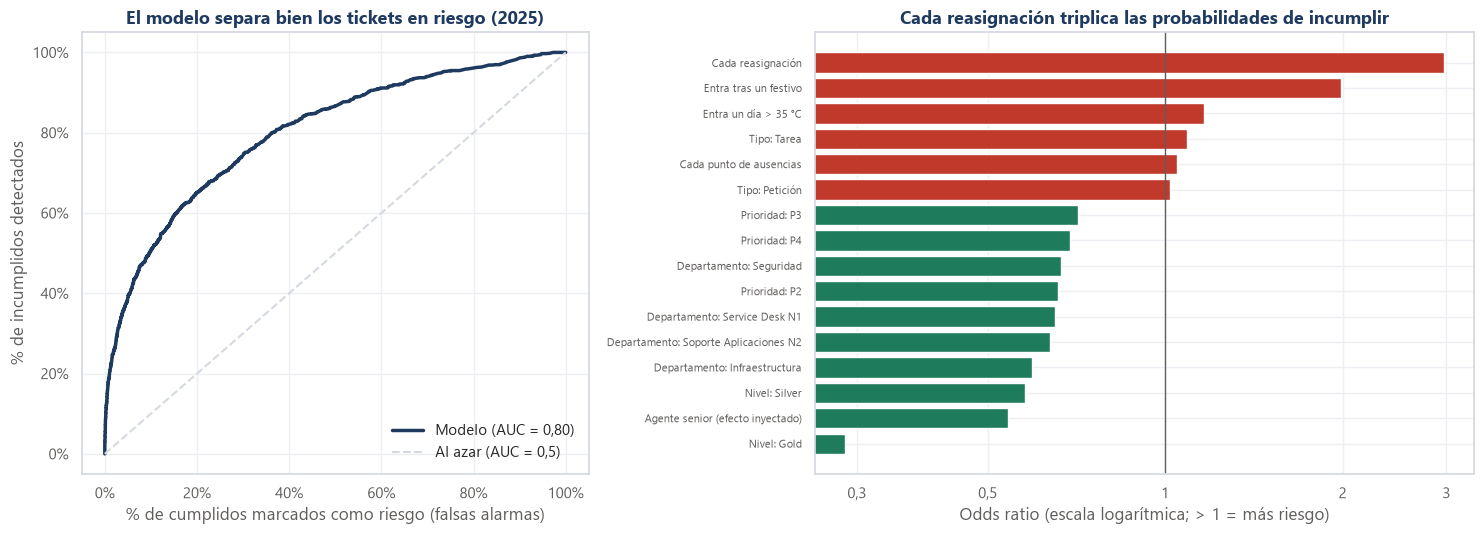

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.3]})

ax = axes[0]
fpr, tpr, _ = roc_curve(medidos7.incumple[prueba], p_prueba)
ax.plot(fpr, tpr, color=AZUL, lw=2.5, label=f"Modelo (AUC = {auc:.2f})".replace(".", ","))
ax.plot([0, 1], [0, 1], color=GRIS_CLARO, ls="--", label="Al azar (AUC = 0,5)")
ax.set(xlabel="% de cumplidos marcados como riesgo (falsas alarmas)", ylabel="% de incumplidos detectados",
       title="El modelo separa bien los tickets en riesgo (2025)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.legend(frameon=False, loc="lower right")

ax = axes[1]
mostrar = odds.drop([c for c in odds.index if c.startswith("seniority_sin")], errors="ignore")
colores = [ROJO if v > 1 else VERDE for v in mostrar]
def etiqueta(v):
    fijas = {"n_reasignaciones": "Cada reasignación", "es_post_festivo": "Entra tras un festivo",
             "es_dia_caluroso": "Entra un día > 35 °C", "pct_agentes_ausentes": "Cada punto de ausencias",
             "seniority_senior": "Agente senior (efecto inyectado)"}
    if v in fijas:
        return fijas[v]
    campo, valor = v.split("_", 1) if not v.startswith("nivel_contrato_") else ("Nivel", v[len("nivel_contrato_"):])
    return f"{campo.capitalize()}: {valor}"
ax.barh([etiqueta(v) for v in mostrar.index], mostrar.values, color=colores)
ax.axvline(1, color=GRIS, lw=1)
ax.set_xscale("log")
ax.set_xticks([0.3, 0.5, 1, 2, 3], ["0,3", "0,5", "1", "2", "3"])
ax.xaxis.set_minor_locator(mtick.NullLocator())
ax.set(xlabel="Odds ratio (escala logarítmica; > 1 = más riesgo)",
       title="Cada reasignación triplica las probabilidades de incumplir")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
guardar(fig, "07_riesgo.png")
plt.show()

### Resultados y conclusiones del bloque 7

- **El modelo muestra una capacidad de discriminación adecuada:** entrenado con 2024 y probado con 2025, que no había visto,
  da un **AUC de 0,80**. En la práctica: revisando solo el **10 % de tickets con más riesgo** se encuentra
  el **44,5 % de los incumplimientos**, cuatro veces más que revisando al azar.
- **Factores asociados a un mayor riesgo:**
  - **Cada reasignación multiplica por 3** las probabilidades de incumplir (lo que ya asomaba en los
    atípicos del bloque 1 y en Desarrollo en el bloque 3).
  - **Entrar el día después de un festivo las duplica** (×2): la cola acumulada del bloque 2.
  - **Gold (×0,29) y Silver (×0,58)** incumplen menos que Bronze: las colas se ordenan por penalización.
  - Cada punto de ausencias suma un 5 % de probabilidades (efecto pequeño por ticket, grande en agosto).
  - El **calor (×1,16) y el tipo de ticket (≈ 1) no tienen un efecto claro** por ticket, coherente con
    el bloque 4.
  - ⚠️ **Agente senior ×0,54: efecto inyectado en el generador**, no un hallazgo sobre el equipo.
- **Tickets abiertos al corte (124 en plazo):** si todos incumplieran habría **7.546 €** en juego; según
  el riesgo del modelo, la penalización esperada es de **987 €**, y **los 15 de más riesgo concentran
  el 57 %**. Más de la mitad tienen 2 o más reasignaciones y casi todos son de clientes Gold o Silver.

**Limitaciones:** la penalización esperada usa la media por ticket incumplido de cada nivel; en realidad
un ticket solo penaliza si hace que su cliente caiga al tramo deficiente en ese sprint (puede costar 0 € o
mucho más). El modelo prioriza bien, pero los € son una estimación.

**Recomendación:** una **lista diaria de escalado preventivo** con los tickets de más riesgo
(reasignados, post-festivo, Gold/Silver), y reducir las reasignaciones con mejor triaje en N1.


**Criterio de modelado:** no se utiliza el porcentaje final de SLA consumido porque no se conoce mientras el ticket sigue abierto. Incluirlo provocaría fuga de información. Las penalizaciones por resolución pueden afectar a incidencias y peticiones de cualquier prioridad en contratos Gold y Silver; Bronze no contempla estas penalizaciones.


## 8 · Hallazgos

Versión completa, con tablas y gráficos, en [`05_docs/insights_findings.md`](../05_docs/insights_findings.md).
Cada hallazgo sigue el formato **dato → interpretación → acción**.

| # | Hallazgo | Dato clave | Acción |
|---|---|---|---|
| 1 | **Las ausencias de personal se relacionan más con el SLA de verano que la temperatura** | Mes a mes r = −0,92 con las ausencias; con las mismas ausencias, el calor duplica las incidencias de Infra pero no mueve el cumplimiento (85,7 % vs 85,3 %) | Gestionar el verano con la política de vacaciones; guardia de Infra con > 35 °C |
| 2 | **La estimación de capacidad limita a cuatro las ausencias simultáneas en agosto** | Para un 93 %: carga ≤ 1,60 tickets/agente/día → 31 disponibles de 35 (ago 2025: 10,4 fuera, 79 %) | Cupo de vacaciones simultáneas o refuerzo temporal |
| 3 | **Las reasignaciones se asocian con un mayor riesgo de incumplimiento** | Odds ratio 2,97; modelo AUC 0,80; el 10 % de más riesgo tiene el 44,5 % de los incumplidos | Lista diaria de escalado preventivo; mejor triaje en N1 |
| 4 | **El departamento con mejor cumplimiento concentra el mayor importe de penalización** | N1: 4,3 % de incumplimiento y 36,6 % de la penalización (volumen); Desarrollo: 32,7 % y 14,8 % | Mejoras pequeñas en N1 (1 punto ≈ 160 tickets/año); revisar escalados a Desarrollo |
| 5 | **Parte de los clientes Gold no alcanza su objetivo contractual** | 7 de 8 Gold bajo el 95 % en 2025; 43 % de sprints deficientes y 18 % al borde; 14 de 22 clientes (todos Gold y Silver) suman el 80 % | Alerta de sprints «al borde»; revisar el objetivo del 95 % en la renovación |
| 6 | **El volumen aumenta un 24 % tras los festivos y disminuye el cumplimiento** | 69 vs 55 tickets un lunes (p = 3·10⁻⁵); 87,0 % vs 93,1 % de cumplimiento; riesgo ×2 | Reforzar el turno el día después de festivos y puentes |
| 7 | **Cinco clientes Bronze presentan características próximas al segmento Silver** | 152–238 usuarios (Silver desde 200), incumplimiento como Silver; silueta 0,33 (estructura débil) | Proponerles pasar a Silver; revisar los Bronze con muchos P1 |

**Balance del periodo:** 10,97 M€ facturados, 74.447 € de bonus, 142.513 € de penalización →
**−68.066 € (−0,62 % de la cuota)**, con el tope del contrato.

**Alcance y limitaciones del análisis:** los datos de negocio son sintéticos con 6 correlaciones inyectadas
(el análisis las detecta y las mide); el efecto senior/junior está inyectado y **no** es un hallazgo; el
calor sin efecto propio y los perfiles débiles se reportan tal cual; 2 años de historia y sin festivos
de 2026 limitan la previsión.